# Чекпойнт №2. Разведочный анализ данных (EDA)

В этом ноутбуке мы проводим разведочный анализ датасета Elliptic, чтобы лучше понять данные, их структуру и особенности перед тем, как переходить к обучению первых ML-моделей.

Ноутбук состоит из четырёх разделов, каждый делал один участник команды.

1. **Качество данных** (Арсений Колышкин). Основные статистики, пропуски, ошибочные значения и выбросы.
2. **Метки, время и дрейф** (Алина Миронова). Баланс классов, неразмеченные транзакции, доля illicit по временным шагам, дрейф признаков и разбиение на train и test.
3. **Анализ признаков, связь с целевой переменной и лучшие признаки** (Александр Борисов). Корреляции признаков с таргетом, сравнение локальных и агрегированных признаков, распределения по классам и рейтинг самых информативных признаков.
4. **Отбор наиболее важных признаков, матрица корреляций, pairplot** (Олег Голещихин). Детрендирование дрейфующих признаков, отбор признаков по разности медиан и по корреляции с таргетом, проверка мультиколлинеарности.

В конце собраны общие выводы по всем разделам и то, как мы планируем использовать их на следующих этапах проекта.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from bitcoin_aml_detection.data import FEATURES, LOCAL_FEATURES, AGG_FEATURES, load_txs, load_edges
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

In [2]:
# Настройки визуализации
sns.set_theme(style="whitegrid", palette="muted")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.ymargin": 0.15,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "font.size": 11,
})

## 1. Качество данных

В первом разделе проверяем данные Elliptic: основные статистики, пропуски, ошибочные значения и выбросы.

### 1.1. Основные статистики

In [3]:
df = load_txs()
df.shape

(203769, 169)

In [4]:
df.dtypes.value_counts()

float64    166
int64        2
object       1
Name: count, dtype: int64

In [5]:
df.head()

,txId,time_step,local_1,local_2,local_3,local_4,local_5,local_6,local_7,local_8,...,agg_65,agg_66,agg_67,agg_68,agg_69,agg_70,agg_71,agg_72,label,y
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,unknown,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,licit,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,unknown,NaN


In [6]:
df.describe(include="all").round(4)

,txId,time_step,local_1,local_2,local_3,local_4,local_5,local_6,local_7,local_8,...,agg_65,agg_66,agg_67,agg_68,agg_69,agg_70,agg_71,agg_72,label,y
count,2.037690e+05,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,...,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769,46564.0000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,157205,NaN
mean,1.711310e+08,23.8440,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0976
std,1.104655e+08,15.1722,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,NaN,0.2968
min,1.076000e+03,1.0000,-0.1730,-0.2106,-1.7564,-0.1220,-0.0637,-0.1130,-0.0616,-0.1636,...,-0.9791,-0.9786,-0.2161,-0.1259,-0.1312,-0.2698,-1.7609,-1.7610,NaN,0.0000
25%,8.433452e+07,9.0000,-0.1725,-0.1803,-1.2014,-0.1220,-0.0439,-0.1130,-0.0616,-0.1635,...,-0.9791,-0.9786,-0.0989,-0.0875,-0.1312,-0.1406,-0.1206,-0.1198,NaN,0.0000
50%,1.624375e+08,23.0000,-0.1692,-0.1329,0.4636,-0.1220,-0.0439,-0.1130,-0.0616,-0.1620,...,0.2411,0.2414,0.0183,-0.0875,-0.1312,-0.0975,-0.1206,-0.1198,NaN,0.0000
75%,2.454798e+08,38.0000,-0.1319,-0.0552,1.0186,-0.1220,-0.0439,-0.1130,-0.0616,-0.1356,...,1.3056,1.3988,0.0183,-0.0875,-0.0847,-0.0975,0.1520,0.1200,NaN,0.0000


In [7]:
groups = {"local": LOCAL_FEATURES, "agg": AGG_FEATURES}

pd.DataFrame({
    name: {
        "признаков": len(columns),
        "наибольший модуль среднего": df[columns].mean().abs().max(),
        "наименьший std": df[columns].std().min(),
        "типичная медиана": df[columns].median().median(),
        "типичный максимум": df[columns].max().median(),
        "самый большой максимум": df[columns].max().max(),
    }
    for name, columns in groups.items()
}).round(3)

,local,agg
признаков,93.000,72.000
наибольший модуль среднего,0.000,0.000
наименьший std,1.000,1.000
типичная медиана,-0.122,-0.090
типичный максимум,15.678,4.049
самый большой максимум,289.204,251.849


Признаки нормализованы (среднее 0, std 1), поэтому значение признака равно его расстоянию от среднего в стандартных отклонениях.

In [8]:
feature_max = df[FEATURES].max()

pd.Series({
    "больше 10 std": (feature_max > 10).sum(),
    "больше 50 std": (feature_max > 50).sum(),
    "больше 100 std": (feature_max > 100).sum(),
    "больше 200 std": (feature_max > 200).sum(),
}, name="число признаков").rename_axis("максимум признака").to_frame()

,число признаков
максимум признака,
больше 10 std,88
больше 50 std,42
больше 100 std,24
больше 200 std,9


In [9]:
top_feature = feature_max.idxmax()
top_feature, (df[top_feature] > 50).sum()

('local_36', np.int64(5))

**Вывод.** В таблице 203 769 транзакций и 169 колонок: 165 признаков, `txId`, `time_step`, `label` и `y`.
Все признаки нормализованы (среднее ~ 0, std ~ 1), константных нет. Большие значения встречаются
часто: у 88 признаков максимум больше 10 стандартных отклонений, у 24 больше 100. У локальных
признаков хвосты обычно длиннее, чем у агрегированных (типичный максимум 15.7 и 4.0). При этом таких
транзакций может быть мало: например, у `local_36`, признака с самым большим максимумом, значений
больше 50 всего 5. Подробнее разберём это в разделе про выбросы.

### 1.2. Пропуски

In [10]:
missing = df.isna().mean().sort_values(ascending=False).round(3)
pd.Series(missing[missing > 0], name="доля пропущенных значений").rename_axis("столбец").to_frame()

,доля пропущенных значений
столбец,
y,0.771


In [11]:
df[FEATURES].isna().sum().sum()

np.int64(0)

In [12]:
pd.crosstab(df["label"], df["y"].isna())

y,False,True
label,,
illicit,4545,0
licit,42019,0
unknown,0,157205


**Вывод.** В признаках пропусков нет (0 во всех 165 колонках), дополнительно заполнять ничего не нужно.
Единственная колонка с пропусками - таргет `y` (77.1%, 157 205 транзакций).
Все они относятся к метке `unknown`, а у `illicit` и `licit` пропусков нет.
Значит, пропуск здесь означает отсутствие разметки, а не ошибку в данных.
Мы не заполняем эти значения и не удаляем строки из таблицы: для обучения и оценки моделей используем только размеченные транзакции.

### 1.3. Ошибочные значения

In [13]:
pd.Series({
    "дубли txId": df["txId"].duplicated().sum(),
    "time_step вне 1..49": (~df["time_step"].between(1, 49)).sum(),
    "значения class вне 1, 2, unknown": (~df["label"].isin(["illicit", "licit", "unknown"])).sum(),
}, name="число нарушений").to_frame()

,число нарушений
дубли txId,0
time_step вне 1..49,0
"значения class вне 1, 2, unknown",0


In [14]:
pd.Series({
    "бесконечные значения": np.isinf(df[FEATURES]).sum().sum(),
    "константные признаки": (df[FEATURES].nunique() == 1).sum(),
}, name="число нарушений").to_frame()

,число нарушений
бесконечные значения,0
константные признаки,0


In [15]:
edges = load_edges()

pd.Series({
    "txId1 нет в таблице": (~edges["txId1"].isin(df["txId"])).sum(),
    "txId2 нет в таблице": (~edges["txId2"].isin(df["txId"])).sum(),
    "связь транзакции с самой собой": (edges["txId1"] == edges["txId2"]).sum(),
    "дубли связей": edges.duplicated().sum(),
}, name="число нарушений").to_frame()

,число нарушений
txId1 нет в таблице,0
txId2 нет в таблице,0
связь транзакции с самой собой,0
дубли связей,0


In [16]:
same_features = df[df.duplicated(subset=FEATURES, keep=False)]

pd.Series({
    "транзакций с одинаковыми признаками": len(same_features),
    "групп одинаковых транзакций": same_features.groupby(FEATURES).ngroups,
    "лишних строк": df.duplicated(subset=FEATURES).sum(),
    "из них licit": (same_features["label"] == "licit").sum(),
    "из них unknown": (same_features["label"] == "unknown").sum(),
    "из них illicit": (same_features["label"] == "illicit").sum(),
}, name="количество").to_frame()

,количество
транзакций с одинаковыми признаками,49
групп одинаковых транзакций,15
лишних строк,34
из них licit,39
из них unknown,10
из них illicit,0


In [17]:
top_share = df[FEATURES].apply(lambda column: column.value_counts(normalize=True).iloc[0])

pd.Series({
    "больше 50% транзакций": (top_share > 0.5).sum(),
    "больше 90% транзакций": (top_share > 0.9).sum(),
    "больше 99% транзакций": (top_share > 0.99).sum(),
}, name="число признаков").rename_axis("одно значение занимает").to_frame()

,число признаков
одно значение занимает,
больше 50% транзакций,76
больше 90% транзакций,6
больше 99% транзакций,1


In [18]:
top_share.nlargest(5).round(3).rename_axis("признак").rename("доля самого частого значения").to_frame()

,доля самого частого значения
признак,
local_15,0.998
local_70,0.976
local_39,0.969
local_38,0.969
local_36,0.968


**Вывод.** Признаки анонимизированы и нормализованы, поэтому задать для них допустимые границы по смыслу
нельзя. Мы проверили то, что можно проверить, нарушений нет. Дублей `txId` нет, все `time_step` лежат
в диапазоне 1–49, значения класса только `1`, `2` и `unknown`. В признаках нет бесконечных значений
и константных колонок. Все транзакции из связей есть в таблице, связей транзакции с самой собой
и повторяющихся связей нет.

Нашлись две особенности, которые не считаем ошибками. У 34 строк признаки полностью повторяют другие
транзакции: всего в таких группах 49 транзакций с разными `txId`, 39 `licit` и 10 `unknown`, противоречащих
друг другу меток нет. Они могут быть просто похожими, поэтому не удаляем их. У 76 признаков одно значение
занимает больше половины транзакций (у `local_15` около 99.8%), и редкие значения таких признаков стоит
учитывать при анализе выбросов. Исправлять в данных ничего не нужно.

### 1.4. Выбросы

In [19]:
q1 = df[FEATURES].quantile(0.25)
q3 = df[FEATURES].quantile(0.75)
iqr = q3 - q1

is_iqr_outlier = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)
nonzero_iqr_share = is_iqr_outlier.loc[:, iqr > 0].mean()

pd.Series({
    "признаков с IQR = 0": (iqr == 0).sum(),
    "признаков с IQR > 0": (iqr > 0).sum(),
    "средняя доля выбросов при IQR > 0": nonzero_iqr_share.mean(),
    "наибольшая доля выбросов при IQR > 0": nonzero_iqr_share.max(),
    "доля транзакций хотя бы с одним выбросом": is_iqr_outlier.any(axis=1).mean(),
}, name="значение").round(3).to_frame()

,значение
признаков с IQR = 0,55.000
признаков с IQR > 0,110.000
средняя доля выбросов при IQR > 0,0.120
наибольшая доля выбросов при IQR > 0,0.403
доля транзакций хотя бы с одним выбросом,0.951


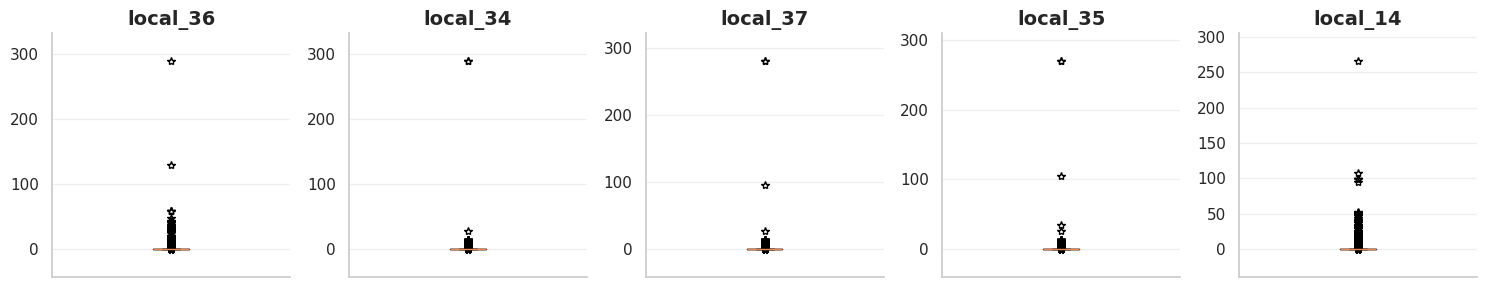

In [20]:
top_features = df[FEATURES].max().nlargest(5).index

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, column in zip(axes, top_features):
    ax.boxplot(df[column], sym="*")
    ax.set_title(column)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

IQR для выбросов здесь не подходит. У 55 признаков IQR равен 0, поэтому выбросом считается любое значение,
отличное от самого частого. Но и у остальных 110 признаков оно отмечает в среднем около 12% значений
(до 40%), потому что распределения сильно скошены. В итоге выброс находится примерно у 95% транзакций.

Дальше считаем значение экстремальным, если оно дальше 3 стандартных отклонений от среднего. Это
условное правило: стандартное отклонение тоже зависит от больших значений, поэтому оно отмечает заметно
большие значения, но не доказывает, что они ошибочны.

In [21]:
is_extreme = df[FEATURES].abs() > 3

extreme_share = is_extreme.mean()
n_extreme = is_extreme.sum(axis=1)

pd.Series({
    "признаков без экстремальных значений": (extreme_share == 0).sum(),
    "медианная доля в признаке": extreme_share.median(),
    "наибольшая доля в признаке": extreme_share.max(),
    "доля транзакций хотя бы с одним": (n_extreme >= 1).mean(),
    "доля транзакций с 20 и более": (n_extreme >= 20).mean(),
}, name="значение").round(4).to_frame()

,значение
признаков без экстремальных значений,45.0000
медианная доля в признаке,0.0078
наибольшая доля в признаке,0.0844
доля транзакций хотя бы с одним,0.3726
доля транзакций с 20 и более,0.0136


In [22]:
pd.DataFrame({
    "доля транзакций с выбросами": (n_extreme >= 1).groupby(df["label"]).mean(),
    "выбросов на транзакцию, в среднем": n_extreme.groupby(df["label"]).mean(),
    "выбросов на транзакцию, медиана": n_extreme.groupby(df["label"]).median(),
}).round(3).rename_axis("метка")

,доля транзакций с выбросами,"выбросов на транзакцию, в среднем","выбросов на транзакцию, медиана"
метка,,,
illicit,0.174,0.589,0.0
licit,0.678,5.868,3.0
unknown,0.297,1.195,0.0


In [23]:
labeled = df["y"].notna()
extreme_group = pd.cut(n_extreme[labeled], bins=[-1, 0, 4, 19, 165], labels=["0", "1–4", "5–19", "20+"])

by_group = pd.crosstab(extreme_group, df.loc[labeled, "label"], normalize="index").round(3)
by_group.index.name = "выбросов в транзакции"
by_group.insert(0, "транзакций", extreme_group.value_counts())
by_group

label,транзакций,illicit,licit
выбросов в транзакции,,,
0,17296,0.217,0.783
1–4,11939,0.050,0.950
5–19,14593,0.013,0.987
20+,2736,0.000,1.000


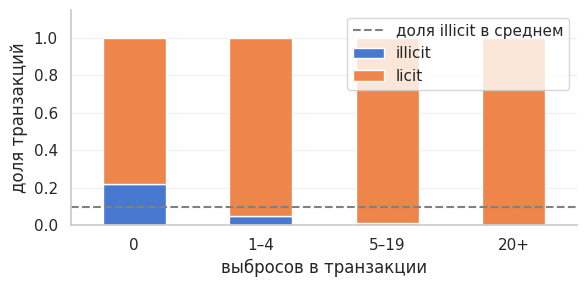

In [24]:
by_group[["illicit", "licit"]].plot.bar(stacked=True, rot=0, figsize=(6, 3))
plt.axhline(df["y"].mean(), color="gray", linestyle="--", label="доля illicit в среднем")
plt.xlabel("выбросов в транзакции")
plt.ylabel("доля транзакций")
plt.grid(axis="x", visible=False)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
df.loc[n_extreme >= 1, "label"].value_counts().rename("удалили бы строк").to_frame()

,удалили бы строк
label,
unknown,46655
licit,28479
illicit,789


**Вывод.** IQR для поиска выбросов нам не подходит. При его использовании выброс находится примерно у 95% транзакций.
По правилу 3 std в отдельном признаке экстремальных значений обычно меньше 1% (медиана 0.78%, максимум 8.44%),
а 45 признаков не содержат их совсем. Но хотя бы одно такое значение есть у 37% транзакций.

Экстремальные значения не указывают на незаконные транзакции, скорее наоборот. Хотя бы одно такое
значение есть у 67.8% `licit` и только у 17.4% `illicit`. Доля `illicit` падает с 21.7% среди транзакций
без экстремальных значений до 0% среди транзакций с 20 и более (2 736 транзакций).

**Решение.** Строки не удаляем: мы потеряли бы 37% транзакций, из них 46 655 `unknown`, 28 479 `licit`
и 789 `illicit`. Почти все удалённые размеченные транзакции оказались бы `licit`, и баланс классов
сильно исказился бы. Значения выглядят как свойство данных, а не как ошибки, поэтому
на этапе EDA оставляем их без изменений. На этапе моделей для деревьев и бустинга ничего делать
не будем, а для логистической регрессии проверим, улучшает ли качество ограничение больших значений.
Параметры ограничения подбираем только на обучающей части, чтобы не было утечки из теста.

### 1.5. Общие выводы по первому разделу

В таблице 203 769 транзакций и 165 признаков. Признаки уже нормализованы, а что они значат, неизвестно.
Пропусков в признаках нет. Пустые значения есть только в `y`: это 77.1% транзакций с меткой `unknown`,
у которых просто нет разметки.

Явных ошибок не нашли. Идентификаторы не повторяются, шаги лежат в диапазоне 1–49, классы и связи
согласованы. Есть 49 транзакций с одинаковыми признаками, но их слишком мало, чтобы на что-то повлиять.
Заметнее другое: у 76 признаков одно значение занимает больше половины строк, поэтому распределения
сильно скошены.

Выбросы тут работают интересно. Интуитивно кажется, что незаконные транзакции чаще будут выделяться большими значениями, но здесь наоборот: такие значения есть у 67.8% `licit` и только у 17.4% `illicit`. Почему так, пока не ясно. Возможно, дело в том, какие транзакции вообще попали в разметку.

Для следующего этапа это значит следующее. Пропуски заполнять и признаки нормализовать повторно не нужно.
Выбросы не будем удалять: иначе потеряем больше трети транзакций, а среди размеченных уйдут почти одни `licit`. Деревьям и бустингу отдаём
признаки как есть, а для логистической регрессии проверим, помогает ли ограничить большие значения.
Почти константные признаки уберём, только если так решит отбор признаков на обучающей части.
Обучаем модели на размеченных транзакциях, а `unknown` оставляем для semi-supervised подходов.

## 2. Метки, время и дрейф

Следующий раздел EDA состоит из пяти подразделов:

1. **Метки.** Сколько у нас незаконных (illicit), легальных (licit) и неразмеченных (unknown) транзакций и на что похожи unknown.
2. **Время.** Как транзакции и доля незаконных транзакций распределены по 49 временным шагам.
3. **Дрейф.** Меняются ли признаки со временем. Если да, модель, обученная на "прошлом", может хуже работать на "будущем".
4. **Разбиение.** Как делить данные на train и test с учётом времени.
5. **Выводы.** Что из всего этого следует для моделей.

### 2.1. Метки и неразмеченные транзакции

Ещё раз посмотрим, сколько всего транзакций в датасете.

In [26]:
print(f'Всего транзакций: {len(df)}')

Всего транзакций: 203769


Посчитаем, сколько транзакций каждого типа и какую долю от всего датасета они составляют.

In [27]:
classes = ["illicit", "licit", "unknown"]

counts = df["label"].value_counts()[classes]
shares = df["label"].value_counts(normalize=True)[classes]

label_table = pd.DataFrame({
    "транзакций": counts,
    "доля от всех": shares.round(3),
})

label_table

,транзакций,доля от всех
label,,
illicit,4545,0.022
licit,42019,0.206
unknown,157205,0.771


In [28]:
# цвета классов
COLORS = {
    "illicit": "#e76f51",
    "licit": "#2a9d8f",
    "unknown": "#b0b0b0",
}

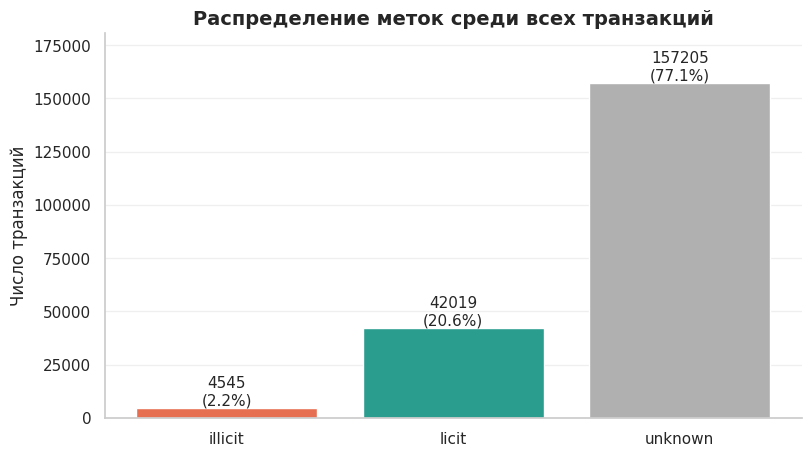

In [29]:
labels = [f"{n}\n({share:.1%})" for n, share in zip(counts.values, shares.values)]

bars = plt.bar(counts.index, counts.values,
               color=[COLORS[c] for c in counts.index])
plt.bar_label(bars, labels=labels)
plt.title("Распределение меток среди всех транзакций")
plt.ylabel("Число транзакций")
plt.grid(axis="x", visible=False)
plt.show()

**Что видим на графике:**

- Размеченных данных немного: метка есть только у 23% транзакций, у остальных 77% метки нет (unknown).

- Незаконных транзакций всего 4 545, это 2.2% от всего датасета.

- Легальных транзакций 42 019, это 20.6% от всего датасета.

Про unknown мы не знаем, легальные они или нет. Там могут быть и те, и другие. Для обычного обучения с учителем они не подходят, но пригодятся в semi-supervised подходах.

Посмотрим только на размеченные транзакции:

In [30]:
labeled_classes = ["illicit", "licit"]

# оставляем только строки, где метка известна
labeled = df[df["label"] != "unknown"]

labeled_counts = labeled["label"].value_counts()[labeled_classes]
labeled_shares = labeled["label"].value_counts(normalize=True)[labeled_classes]

labeled_table = pd.DataFrame({
    "транзакций": labeled_counts,
    "доля среди размеченных": labeled_shares.round(3),
})

In [31]:
print(f"Размеченных транзакций: {len(labeled)}")

Размеченных транзакций: 46564


In [32]:
labeled_table

,транзакций,доля среди размеченных
label,,
illicit,4545,0.098
licit,42019,0.902


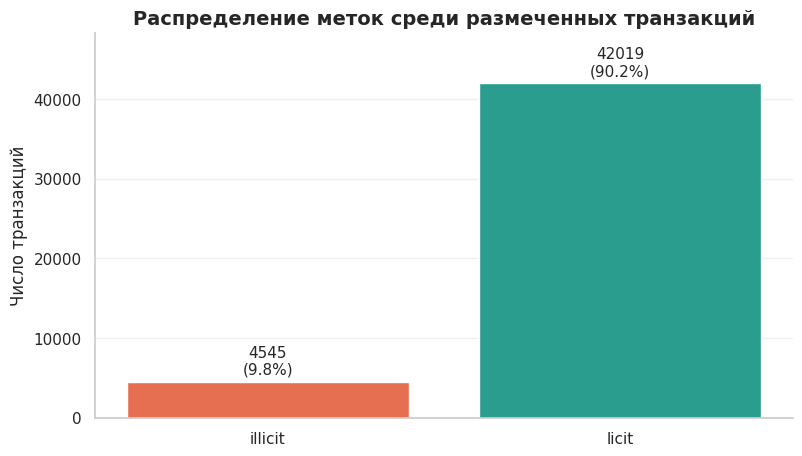

In [33]:
labels = [f"{n}\n({share:.1%})" for n, share in zip(labeled_counts.values, labeled_shares.values)]

bars = plt.bar(labeled_counts.index, labeled_counts.values,
               color=[COLORS[c] for c in labeled_counts.index])
plt.bar_label(bars, labels=labels, padding=3)
plt.title("Распределение меток среди размеченных транзакций")
plt.ylabel("Число транзакций")
plt.grid(axis="x", visible=False)
plt.show()

**Что видим на графике:**

- Среди размеченных транзакций незаконных 4 545, это 9.8%.
- Легальных транзакций 42 019, это 90.2%.
- На одну незаконную транзакцию приходится примерно 9 легальных, так что классы сильно несбалансированы.

Из-за этого accuracy не подходит как метрика: модель, которая всегда отвечает "licit", угадает 90% транзакций и не найдёт ни одной незаконной. Поэтому качество моделей будем оценивать по precision, recall, F1 и PR-AUC для класса illicit.

#### Что такое unknown

Пропущенные значения в датасете встречаются только в столбце с таргетом `y`. Это как раз unknown, 157 205 транзакций (77.1%), в признаках пропусков нет. Выше было отмечено, что про unknown неизвестно, легальные они или нет. Но можно попытаться разобраться, почему у них нет метки и на какой класс они больше похожи по признакам.

Сначала важно понять, **откуда берутся метки**. В статье про датасет ([Weber and Domeniconi, et al., 2019](https://arxiv.org/abs/1908.02591)) транзакция считается licit, если тот, кто её отправил (владелец ключей от входных адресов), относится к легальной категории вроде бирж, кошельков, майнеров и легальных сервисов. Если отправитель связан со скамом, вредоносным ПО, ransomware, финансовыми пирамидами или террористическими организациями, транзакция считается illicit. Про остальные транзакции авторы пишут только, что метки у них нет, и не объясняют почему.

Ещё авторы упоминают, что при разметке использовались эвристики. Например, много входов и повторное использование адресов обычно говорят о легальном участнике вроде биржи, а у незаконных транзакций входов чаще меньше. Значит, метка могла появиться у транзакции в том числе из-за её признаков, и размеченные транзакции могут заметно отличаться от неразмеченных.

Получается, что метку ставили не наугад, а только тем транзакциям, которые удалось связать с известным участником, и в том числе по их признакам.

**Гипотеза:** Пропуски в `y` не случайны. Unknown по признакам отличаются от размеченных транзакций и не являются обычной смесью licit и illicit.

Если бы метки, наоборот, пропускали случайно, unknown выглядели бы как обычная смесь licit и illicit, то есть в основном как licit, ведь незаконных транзакций мало. Проверим, так ли это.

Сначала найдём признаки, по которым licit и illicit различаются. Для этого для каждого признака посчитаем статистику Колмогорова-Смирнова (KS). Она сравнивает два распределения и показывает самый большой разрыв между ними. 0 значит, что распределения совпадают, а чем ближе к 1, тем сильнее они различаются. Подробнее о статистике в разделе 3, где она понадобится для анализа дрейфа.

In [34]:
licit_df = df[df["label"] == "licit"]
illicit_df = df[df["label"] == "illicit"]

ks_licit_illicit = []

for feature in FEATURES:
    ks = ks_2samp(licit_df[feature], illicit_df[feature]).statistic
    ks_licit_illicit.append({"feature": feature, "KS": ks})

ks_licit_illicit = pd.DataFrame(ks_licit_illicit).sort_values("KS", ascending=False)

ks_licit_illicit.head()

,feature,KS
52,local_53,0.617084
54,local_55,0.613535
40,local_41,0.594959
46,local_47,0.593686
89,local_90,0.593160


Возьмём признаки, по которым licit и illicit заметно различаются (KS > 0.2). Если бы unknown были обычной смесью, где около 90% licit, то на каждом таком признаке они были бы ближе к licit, чем к illicit. Посчитаем, так ли это.

In [35]:
unknown_df = df[df["label"] == "unknown"]

# признаки, по которым licit и illicit заметно различаются
strong_features = ks_licit_illicit[ks_licit_illicit["KS"] > 0.2]["feature"]

closer_to_licit = 0
closer_to_illicit = 0

for feature in strong_features:
    ks_to_licit = ks_2samp(unknown_df[feature], licit_df[feature]).statistic
    ks_to_illicit = ks_2samp(unknown_df[feature], illicit_df[feature]).statistic

    if ks_to_licit < ks_to_illicit:
        closer_to_licit += 1
    else:
        closer_to_illicit += 1


In [36]:
print(f"Признаков, где licit и illicit заметно различаются: {len(strong_features)}")
print(f"Из них unknown ближе к licit: {closer_to_licit}")
print(f"Из них unknown ближе к illicit: {closer_to_illicit}")

Признаков, где licit и illicit заметно различаются: 113
Из них unknown ближе к licit: 68
Из них unknown ближе к illicit: 45


**Что видим:**

- Из 113 признаков, по которым licit и illicit заметно различаются, unknown ближе к licit на 68, а ближе к illicit на 45.
- Если бы unknown были обычной смесью, где около 90% licit, ближе к illicit они не оказались бы почти ни на одном признаке. А таких признаков 45, это примерно 40%.

Значит, гипотеза подтверждается, пропуски в метке не случайны. Unknown - это не просто транзакции, которым забыли поставить метку, а транзакции, которые по своим свойствам отличаются от размеченных.

Поэтому пропуски в `y` мы не заполняем. Модели с учителем обучаем только на размеченных транзакциях, а unknown используем в semi-supervised подходах, учитывая, что они отличаются от размеченных.

**Итого:** размечено около 23% транзакций, а среди размеченных незаконных транзакций всего около 10%, так что классы сильно несбалансированы. Остальные 77% - unknown, и пропуски в их метке не случайны, по признакам они заметно отличаются от размеченных транзакций. Поэтому для моделей с учителем используем только размеченные данные, а unknown пригодятся в semi-supervised подходах.

### 2.2. Транзакции во времени

Каждая транзакция относится к одному из 49 временных шагов. Один шаг - это примерно две недели. Посмотрим, как транзакции распределены по шагам и меняется ли со временем доля незаконных.

Сначала посчитаем, сколько транзакций каждого типа приходится на каждый шаг.

In [37]:
# crosstab считает, сколько транзакций каждого типа на каждом шаге
by_step = pd.crosstab(df["time_step"], df["label"])[classes]

by_step.head(10)

label,illicit,licit,unknown
time_step,,,
1,17,2130,5733
2,18,1099,3427
3,11,1268,5342
4,30,1410,4253
5,8,1874,4921
6,5,480,3843
7,102,1101,4845
8,67,1098,3292
9,248,530,4218


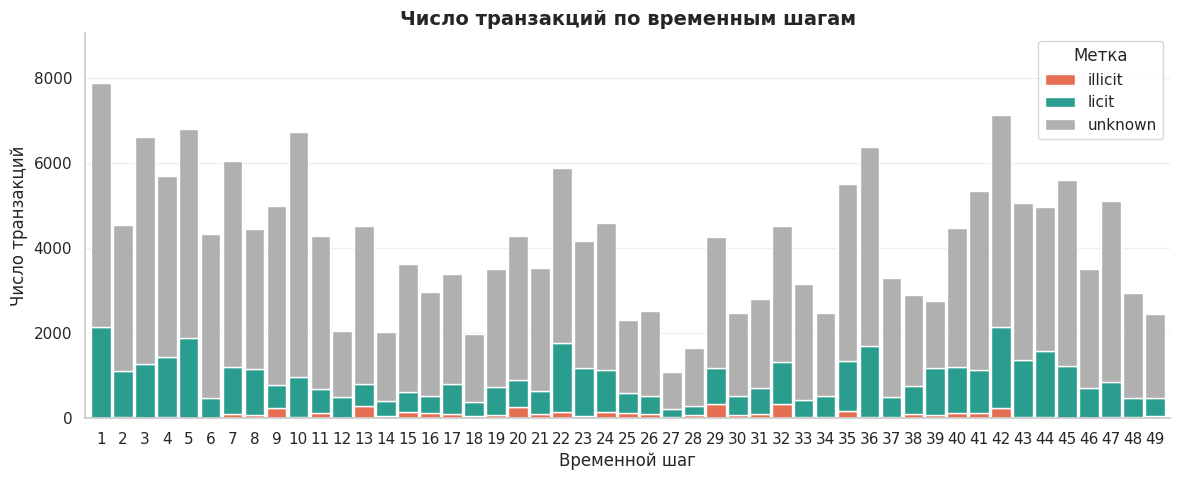

In [38]:
ax = by_step.plot(kind="bar", stacked=True, width=0.9, figsize=(14, 5),
                  color=[COLORS[c] for c in classes])
plt.grid(axis="x", visible=False)
plt.xticks(rotation=0)
plt.title("Число транзакций по временным шагам")
plt.xlabel("Временной шаг")
plt.ylabel("Число транзакций")
plt.legend(title="Метка")
plt.show()

**Что видим на графике:**

- Число транзакций на шаге сильно скачет: от примерно 1 000 (шаг 27) до почти 8 000 (шаг 1).
- На каждом шаге большую часть составляют unknown, размеченных обычно примерно меньше трети.
- Незаконных транзакций так мало, что на графике их почти не видно. Поэтому долю illicit по шагам надо посмотреть отдельно.

Посмотрим, какую долю незаконные транзакции составляют среди размеченных на каждом шаге.

In [39]:
# illicit y = 1, licit y = 0, поэтому среднее y на шаге = доля illicit
illicit_share = labeled.groupby("time_step")["y"].mean() * 100

In [40]:
illicit_share.head(15)

time_step
1      0.791803
2      1.611459
3      0.860047
4      2.083333
5      0.425080
6      1.030928
7      8.478803
8      5.751073
9     31.876607
10     1.851852
11    18.821839
12     3.162055
13    35.970334
14    10.311751
15    23.786408
Name: y, dtype: float64

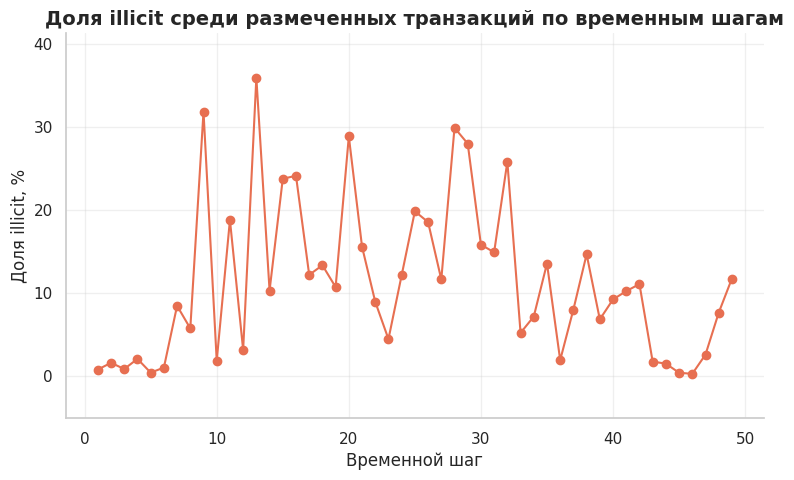

In [41]:
plt.plot(illicit_share.index, illicit_share.values,
         marker="o", color=COLORS["illicit"])
plt.title("Доля illicit среди размеченных транзакций по временным шагам")
plt.xlabel("Временной шаг")
plt.ylabel("Доля illicit, %")
plt.show()

**Что видим на графике:**

- Доля illicit от шага к шагу меняется очень сильно: от почти 0% до 36% (шаг 13).
- На первых шагах (1-6) незаконных транзакций почти нет, около 2% и меньше.
- С 43-го шага доля illicit резко падает почти до нуля и только к последним шагам снова немного поднимается. Авторы датасета ([Weber and Domeniconi, et al., 2019](https://arxiv.org/abs/1908.02591)) объясняют это закрытием крупного даркнет-рынка на 43-м шаге. После него все модели начинают работать плохо, даже если их переобучать на каждом новом шаге.

Получается, что данные со временем меняются, поэтому случайное разбиение на train и test здесь не подходит, делить нужно по времени. Также качество модели на тесте лучше смотреть не только в целом, но и отдельно по каждому шагу. Так будет видно, на каких шагах модель работает хорошо, а на каких плохо.

**Итого:** транзакции распределены по шагам неравномерно, их число сильно скачет от шага к шагу. Доля незаконных транзакций со временем тоже не постоянна, на первых шагах их почти нет, в середине бывает до 30% и больше, а с 43-го шага доля резко падает почти до нуля и только к последним шагам снова немного поднимается. Значит, данные меняются со временем, и это нужно учитывать при разбиении на train и test.

### 2.3. Временной дрейф

**Временной дрейф** - это когда данные со временем меняются, и модель, обученная на прошлом, начинает хуже работать на будущем.

Меняться может разное. Может измениться доля классов: например, незаконных транзакций станет меньше. Могут измениться сами признаки: транзакции в целом начнут выглядеть иначе. Может измениться то, чем незаконные транзакции отличаются от легальных: мошенники сменят тактику, и старые закономерности перестанут работать.

Изменение доли классов мы уже видели в прошлом разделе. Здесь проверим, меняются ли со временем сами признаки.


Что именно означает каждый признак, **неизвестно**, так как Elliptic не раскрывает это из-за коммерческой тайны. Известно только, что локальные признаки описывают саму транзакцию (число входов и выходов, комиссию, объём перевода и т. п.), а агрегированные - её соседей в графе. Поэтому мы увидим, какие признаки сдвинулись со временем, но не сможем сказать, что именно за ними стоит.

Для сравнения делим шаги на **два периода**: ранние (1-34) и поздние (35-49). Это стандартная граница из статьи про датасет, её же потом используем для train/test split.

In [42]:
print(f"Всего признаков: {len(FEATURES)}")
print(f"Локальных: {len(LOCAL_FEATURES)}")
print(f"Агрегированных: {len(AGG_FEATURES)}")

Всего признаков: 165
Локальных: 93
Агрегированных: 72


In [43]:
early = df[df["time_step"] <= 34]
late = df[df["time_step"] >= 35]

early_share = len(early) / len(df) * 100
late_share = len(late) / len(df) * 100

print(f"Ранние шаги (1-34): {len(early)} транзакций ({early_share:.1f}%)")
print(f"Поздние шаги (35-49): {len(late)} транзакций ({late_share:.1f}%)")

Ранние шаги (1-34): 136265 транзакций (66.9%)
Поздние шаги (35-49): 67504 транзакций (33.1%)


Для каждого признака сравним его распределение в ранних и поздних шагах с помощью статистики Колмогорова-Смирнова (KS), которую мы уже использовали в разделе 1. Разберём подробнее, как она считается.

Она показывает максимальный разрыв между двумя распределениями, 0 значит, что распределения совпадают, а чем ближе к 1, тем сильнее они различаются.

$$
D = \max_x \left| F_{\text{ранние}}(x) - F_{\text{поздние}}(x) \right|
$$

Здесь $x$ - любое значение признака, $F(x)$ - доля значений признака, которые меньше или равны $x$. Для каждого периода строится такая кривая, и $D$ - это самое большое расстояние между ними по вертикали, если перебрать все возможные $x$.

Был выбран KS, потому что он сравнивает распределения целиком, а не только средние, не требует, чтобы данные были нормально распределены, и всегда даёт число от 0 до 1. Поэтому признаки можно сравнивать между собой и найти те, что дрейфуют сильнее всего.

In [44]:
ks_results = []

for feature in FEATURES:
    result = ks_2samp(early[feature], late[feature])
    ks_results.append({"feature": feature, "KS": result.statistic})

drift = pd.DataFrame(ks_results).sort_values("KS", ascending=False)

drift.head(15)

,feature,KS
135,agg_43,0.996319
100,agg_8,0.995941
102,agg_10,0.994667
99,agg_7,0.992593
138,agg_46,0.965548
136,agg_44,0.930235
1,local_2,0.604995
105,agg_13,0.573018
108,agg_16,0.556302
106,agg_14,0.533597


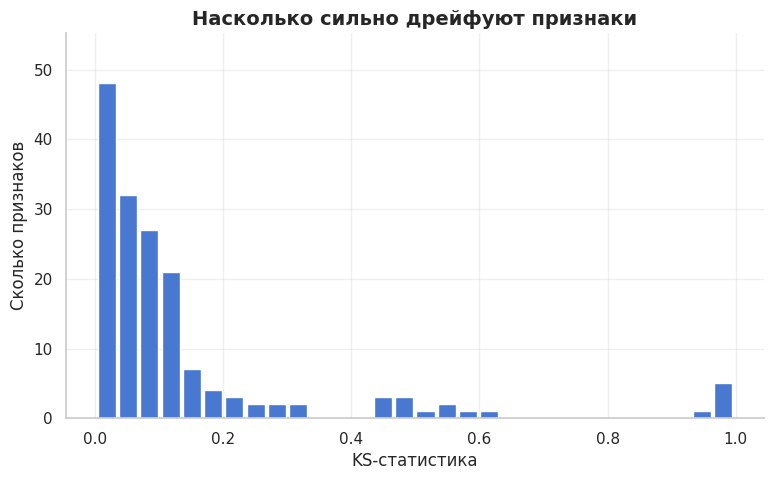

In [45]:
plt.hist(drift["KS"], bins=30, rwidth=0.85)
plt.title("Насколько сильно дрейфуют признаки")
plt.xlabel("KS-статистика")
plt.ylabel("Сколько признаков")
plt.show()

In [46]:
weak = (drift["KS"] < 0.1).sum()
small = ((drift["KS"] >= 0.1) & (drift["KS"] < 0.2)).sum()
noticeable = ((drift["KS"] >= 0.2) & (drift["KS"] < 0.4)).sum()
strong = ((drift["KS"] >= 0.4) & (drift["KS"] < 0.9)).sum()
extreme = (drift["KS"] >= 0.9).sum()

print(f"Почти не меняются (KS < 0.1): {weak}")
print(f"Слабый дрейф (0.1-0.2): {small}")
print(f"Заметный дрейф (0.2-0.4): {noticeable}")
print(f"Сильный дрейф (0.4-0.9): {strong}")
print(f"Распределения почти не пересекаются (KS >= 0.9): {extreme}")

Почти не меняются (KS < 0.1): 105
Слабый дрейф (0.1-0.2): 34
Заметный дрейф (0.2-0.4): 9
Сильный дрейф (0.4-0.9): 11
Распределения почти не пересекаются (KS >= 0.9): 6


**Что видим на графике:**

- Большинство признаков со временем меняются мало. У 105 признаков KS меньше 0.1, то есть они почти не меняются, ещё у 34 KS от 0.1 до 0.2, это слабый дрейф. Вместе это 139 из 165.
- У 20 признаков дрейф уже ощутимый. У 9 из них KS от 0.2 до 0.4, у 11 от 0.4 до 0.9.
- Справа особняком стоят 6 признаков с KS больше 0.9. Их значения в ранних и поздних шагах почти не пересекаются, и это выглядит подозрительно.

В целом признаки довольно стабильны, но часть из них со временем заметно сдвигается, и это может ухудшить качество модели на новых данных.

Пороги 0.1, 0.2, 0.4 и 0.9 были выбраны для удобства, общепринятой шкалы для KS нет.

#### Как выглядит дрейф на примерах

KS сводит изменение признака к одному числу. Чтобы понять, что за ним стоит, посмотрим на три признака с разным KS - почти без дрейфа, с сильным дрейфом и с самым большим KS.

Для каждого признака построим boxplot по шагам. Ящик показывает, где лежит средняя половина значений на шаге, линия внутри - медиану, усы - общий разброс.

In [47]:
def plot_box_by_step(feature):
    # для каждого шага собираем значения признака
    values_by_step = [df.loc[df["time_step"] == step, feature] for step in range(1, 50)]

    ks = drift.loc[drift["feature"] == feature, "KS"].iloc[0]

    plt.figure(figsize=(14, 5))
    plt.boxplot(values_by_step, showfliers=False)
    plt.axvline(34.5, color="gray", linestyle="--",
                label="граница ранних и поздних шагов")
    plt.title(f"Значения {feature} по временным шагам (KS = {ks:.2f})")
    plt.xlabel("Временной шаг")
    plt.ylabel("Значение признака")
    plt.legend()
    plt.grid(axis="x", visible=False)
    plt.show()

Для начала возьмём признак почти без дрейфа

In [48]:
drift[(drift["KS"] > 0.02) & (drift["KS"] < 0.05)].head(5)

,feature,KS
15,local_16,0.049869
95,agg_3,0.048366
139,agg_47,0.048347
17,local_18,0.047509
159,agg_67,0.046754


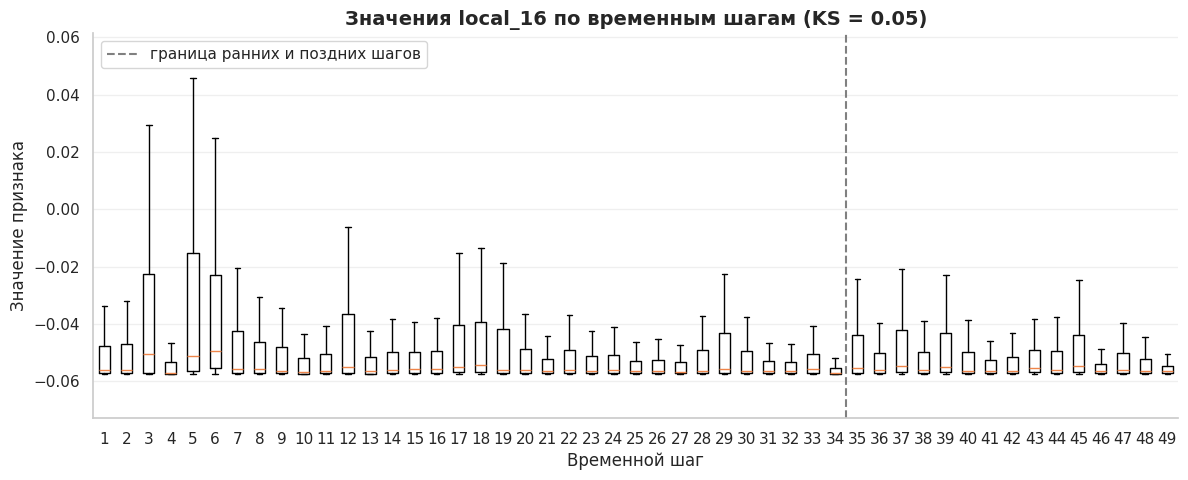

In [49]:
plot_box_by_step("local_16")

**Что видим на графике:**

- Медиана на всех шагах держится примерно на одном уровне у нижней границы значений.
- Размер ящиков и усов меняется от шага к шагу, на некоторых шагах (3, 5, 6, 12, 17-19) разброс заметно больше. Но это скачки, а не постепенное изменение.
- Слева и справа от границы картина примерно одинаковая, поздние шаги не выглядят как-то особенно.

Поэтому KS у этого признака маленький. Так выглядит признак без дрейфа, значения немного колеблются, но со временем систематически не меняются.

`local_2` - один из признаков с сильным дрейфом.

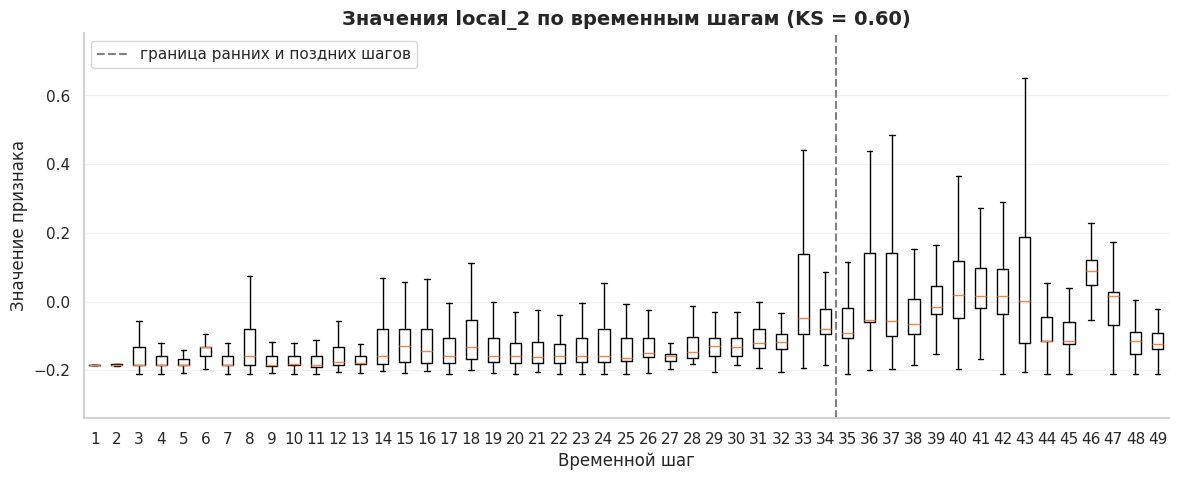

In [50]:
plot_box_by_step("local_2")

**Что видим на графике:**

- На шагах 1-32 значения `local_2` у большинства транзакций близки к минимуму, около -0.2, и почти не различаются. Разброс постепенно растёт, но остаётся небольшим.
- Примерно с 33-го шага признак резко меняется. Разброс становится намного больше, а медиана на шагах 40-43 поднимается почти до 0.
- После 43-го шага значения частично возвращаются вниз, но разброс всё равно больше, чем в начале.

Изменение начинается почти ровно на границе ранних и поздних шагов, поэтому KS у этого признака и получился таким большим. При обучении на шагах 1-34 модель почти не видит больших значений `local_2`, а на тестовых шагах они встречаются постоянно.

`agg_43` - признак с самым большим KS.

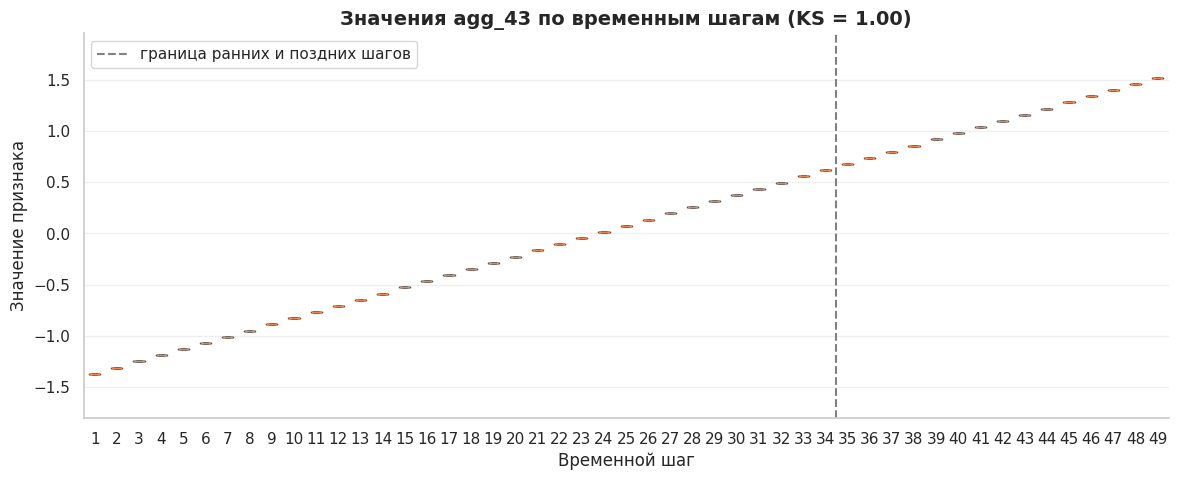

In [51]:
plot_box_by_step("agg_43")

**Что видим на графике:**

- На каждом шаге ящик сжат в тонкую чёрточку, то есть почти у всех транзакций шага значение `agg_43` одинаковое.
- От шага к шагу значение растёт ровно, каждый раз на одну и ту же величину, как будто это просто номер шага в другом масштабе.

Для сравнения, у `local_2` внутри шага большой разброс, а меняется он скачками. Здесь же никакого разброса нет, только ровная лесенка.

#### Признаки с KS больше 0.9

У шести признаков KS больше 0.9, то есть их значения в ранних и поздних шагах почти не пересекаются. Для обычной характеристики транзакции это очень странно, поэтому разберёмся с ними отдельно.

In [52]:
strange = list(drift[drift["KS"] > 0.9]["feature"])

print(f"Признаков с KS > 0.9: {len(strange)}")
drift[drift["KS"] > 0.9]

Признаков с KS > 0.9: 6


,feature,KS
135,agg_43,0.996319
100,agg_8,0.995941
102,agg_10,0.994667
99,agg_7,0.992593
138,agg_46,0.965548
136,agg_44,0.930235


Посмотрим, как медиана этих признаков меняется от шага к шагу.

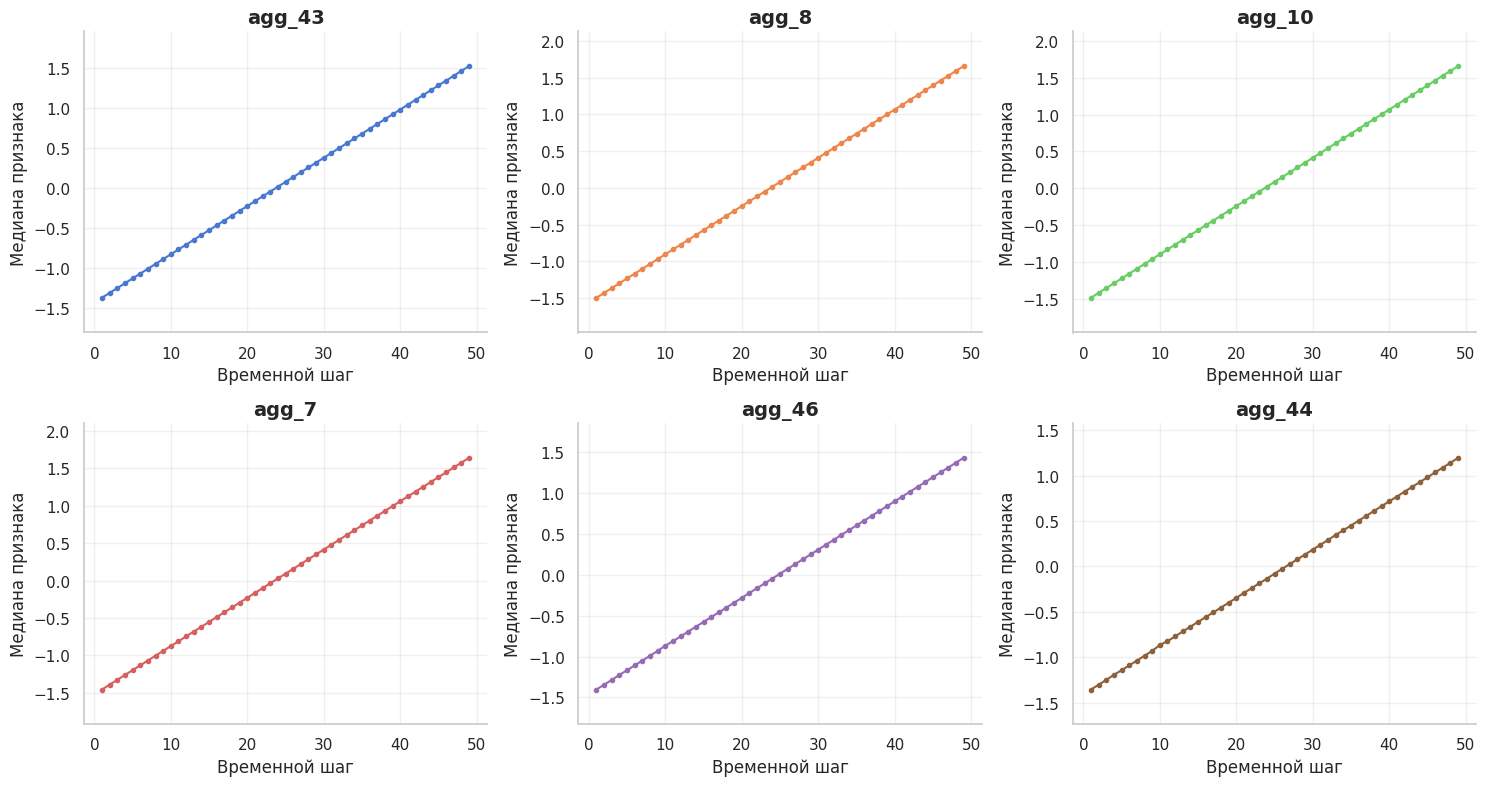

In [53]:
medians = df.groupby("time_step")[strange].median()

axes = medians.plot(subplots=True, layout=(2, 3), figsize=(15, 8), sharex=False,
                    marker="o", markersize=3, legend=False)

for ax, feature in zip(axes.flatten(), strange):
    ax.set_title(feature)
    ax.set_xlabel("Временной шаг")
    ax.set_ylabel("Медиана признака")

plt.tight_layout()
plt.show()

Медиана всех шести признаков растёт идеально ровной линией. Это больше похоже на сам номер шага. Проверим это через корреляцию с `time_step`.

In [54]:
time_corr = df[FEATURES].corrwith(df["time_step"])
# берём модуль
time_corr = time_corr.abs().sort_values(ascending=False)

time_corr.head(10)

agg_8      0.994448
agg_10     0.992579
agg_7      0.982430
agg_43     0.911859
agg_46     0.890583
agg_44     0.788108
agg_22     0.580025
local_3    0.573155
agg_58     0.571132
agg_19     0.562550
dtype: float64

У первых шести признаков корреляция от 0.79 до 0.99, а дальше резкий обрыв до 0.58. Но у части признаков она ниже, чем можно ожидать по идеально ровным графикам. Корреляция Пирсона чувствительна к выбросам, поэтому посмотрим ещё корреляцию Спирмена. Она сравнивает не сами значения, а их порядок, и выбросы на неё почти не влияют.

In [55]:
time_corr_spearman = df[FEATURES].corrwith(df["time_step"], method="spearman")
time_corr_spearman = time_corr_spearman.abs().sort_values(ascending=False)

time_corr_spearman.head(10)

agg_8      0.997643
agg_10     0.996520
agg_7      0.995038
agg_43     0.994883
agg_46     0.970433
agg_44     0.901884
local_2    0.630863
agg_13     0.603780
agg_16     0.603573
agg_14     0.570641
dtype: float64

По Спирмену у этих шести признаков корреляция от 0.90 до 0.99, а у следующего уже 0.63.

Посмотрим на сами значения

In [56]:
df[["time_step"] + strange].sample(10, random_state=42).sort_values("time_step")

,time_step,agg_43,agg_8,agg_10,agg_7,agg_46,agg_44
16006,3,-1.253084,-1.362709,-1.354981,-1.328785,-1.273486,-1.226776
26188,5,-1.132237,-1.231329,-1.223958,-1.199584,-1.157091,-1.123787
28018,5,-1.132296,-1.231622,-1.224251,-1.199872,-1.166000,-1.139749
45400,8,-0.951174,-1.048784,-1.361049,-3.772772,-0.990587,-0.983659
125292,31,0.438007,0.475768,0.478497,0.479192,0.421479,0.333387
128361,32,0.498191,0.541133,0.543684,0.543473,0.426827,0.290085
139710,35,0.679613,0.738431,0.740445,0.737498,0.604188,0.449415
169766,42,2.053276,1.198034,1.198799,1.189476,2.057206,1.853725
180721,44,1.223098,1.329284,1.329692,1.318549,1.136171,0.927905
196048,47,1.426119,1.526159,1.526032,1.512157,1.734863,1.825673


**Что видим в таблице:**

- Чем больше номер шага, тем больше значения всех шести признаков. На 3-м шаге они около -1.3, на 31-м около 0.45, на 47-м около 1.5.
- У двух транзакций с 5-го шага значения почти совпадают, различие только в третьем-четвёртом знаке после запятой.
- Иногда встречаются выбросы. У транзакции с 8-го шага `agg_7` равен -3.77, хотя у остальных признаков около -1. А на 42-м шаге `agg_43`, `agg_46` и `agg_44` около 2, хотя `agg_8` и `agg_10` около 1.2.

Получается, что значения этих признаков в основном определяются номером шага, а редкие выбросы как раз объясняют, почему корреляция Пирсона у части признаков ниже, чем у Спирмена.

In [57]:
# стандартизация: вычитаем среднее и делим на стандартное отклонение
time_scaled = (df["time_step"] - df["time_step"].mean()) / df["time_step"].std()

comparison = pd.DataFrame({"time_step": df["time_step"],
                           "time_step стандартиз.": time_scaled})

for feature in strange:
    comparison[feature] = df[feature]

comparison.groupby("time_step").median().head(10)

,time_step стандартиз.,agg_43,agg_8,agg_10,agg_7,agg_46,agg_44
time_step,,,,,,,
1,-1.505649,-1.373812,-1.494057,-1.486037,-1.458049,-1.403801,-1.354866
2,-1.439739,-1.313478,-1.428497,-1.420655,-1.393545,-1.345208,-1.302661
3,-1.373829,-1.253084,-1.362774,-1.355095,-1.328945,-1.285970,-1.249217
4,-1.307918,-1.192690,-1.297149,-1.289665,-1.264376,-1.225150,-1.192982
5,-1.242008,-1.132267,-1.231492,-1.224153,-1.199776,-1.167748,-1.142910
6,-1.176098,-1.072052,-1.165899,-1.158707,-1.135240,-1.108696,-1.089756
7,-1.110188,-1.011419,-1.100209,-1.093195,-1.070639,-1.049588,-1.036839
8,-1.044278,-0.951025,-1.034584,-1.027749,-1.006135,-0.990308,-0.983369
9,-0.978368,-0.890631,-0.968894,-0.962237,-0.941503,-0.931173,-0.930057


In [58]:
# медианы по шагам
step_medians = comparison.groupby("time_step").median()
step_medians.diff().mean().round(3)

time_step стандартиз.    0.066
agg_43                   0.060
agg_8                    0.066
agg_10                   0.065
agg_7                    0.065
agg_46                   0.059
agg_44                   0.053
dtype: float64

**Что видим в таблице:**

- Медианы всех шести признаков растут от шага к шагу почти на одну и ту же величину.
- У `agg_8`, `agg_10` и `agg_7` значения почти совпадают со стандартизированным номером шага, разница не больше 0.05.

Значит, все шесть признаков почти полностью определяются номером шага, просто каждый в своём масштабе.

Получается, что эти признаки описывают не саму транзакцию, а фактически момент времени. Из-за этого их нельзя использовать в модели по той же причине, что и `time_step`. Модель может запомнить, в какие периоды было много незаконных транзакций, а на тестовых шагах у этих признаков будут значения, которых она не видела при обучении.

Дальше в анализе дрейфа эти шесть признаков не рассматриваются.

#### Дрейф остальных признаков

Убираем шесть признаков, которые кодируют время, и смотрим, какие признаки сильнее всего дрейфуют среди оставшихся.

In [59]:
real_drift = drift[~drift["feature"].isin(strange)]

real_drift.head(15)

,feature,KS
1,local_2,0.604995
105,agg_13,0.573018
108,agg_16,0.556302
106,agg_14,0.533597
141,agg_49,0.511467
111,agg_19,0.485940
114,agg_22,0.472537
2,local_3,0.469738
147,agg_55,0.461056
150,agg_58,0.457536


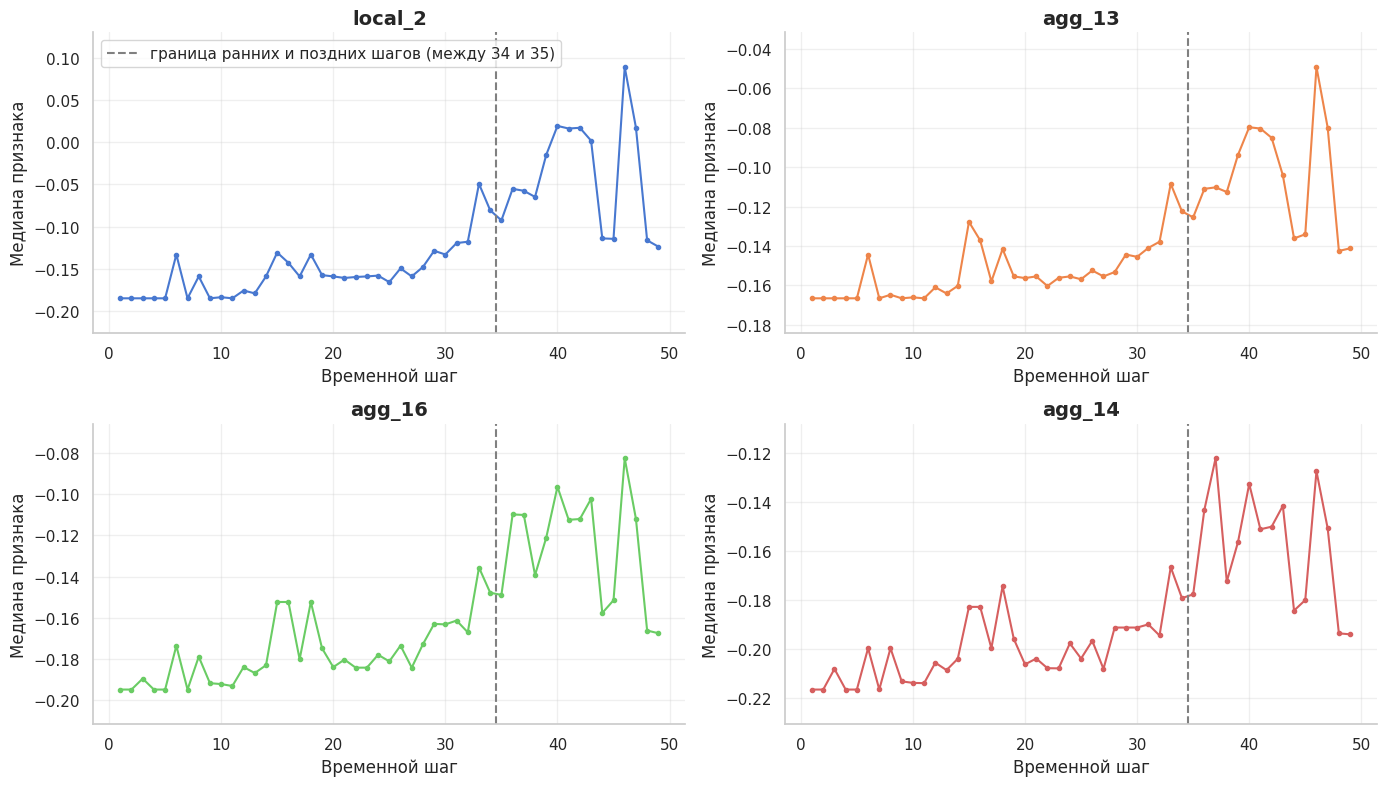

In [60]:
top_features = list(real_drift["feature"].head(4))

medians = df.groupby("time_step")[top_features].median()

axes = medians.plot(subplots=True, layout=(2, 2), figsize=(14, 8), sharex=False,
                    marker="o", markersize=3, legend=False)

for ax, feature in zip(axes.flatten(), top_features):
    ax.set_title(feature)
    border = ax.axvline(34.5, color="gray", linestyle="--",
                        label="граница ранних и поздних шагов (между 34 и 35)")
    ax.set_xlabel("Временной шаг")
    ax.set_ylabel("Медиана признака")

axes.flatten()[0].legend(handles=[border])
plt.tight_layout()
plt.show()

**Что видим на графике:**

- На ранних шагах медиана всех четырёх признаков почти не меняется. Есть отдельные всплески (около 6-8 и 15-18 шагов), но потом значения возвращаются обратно.
- Примерно с 25-го шага медиана начинает постепенно расти, а после границы периодов поднимается заметно выше, чем было на ранних шагах.
- На поздних шагах значения сильно скачут. Пики приходятся примерно на шаги 40-43 и 46, а к последним шагам медиана снова опускается, хотя у большинства признаков остаётся выше, чем в начале.

Все четыре признака меняются почти одинаково, возможно они описывают похожие характеристики транзакций. В отличие от шести признаков с KS больше 0.9, здесь нет ровной прямой, значения меняются неравномерно и со скачками. Это больше похоже на реальное изменение транзакций со временем, то есть на настоящий дрейф.


#### Дрейф признаков отдельно для licit и illicit

Общий KS смешивает две вещи. Признак может сдвинуться потому, что изменились сами транзакции, а может потому, что на поздних шагах другое соотношение классов. Мы уже видели, что illicit на поздних шагах меньше. Если licit и illicit сильно отличаются по признаку, то одно только изменение их доли уже сдвинет общее распределение, даже если внутри каждого класса ничего не поменялось.

Чтобы разделить эти эффекты, посчитаем KS между ранними и поздними шагами отдельно для licit и отдельно для illicit. Дрейф внутри illicit особенно важен. Он может значить, что незаконные транзакции со временем стали выглядеть иначе, и модель, обученная на старых схемах, будет хуже находить новые.

Шесть признаков, повторяющих номер шага, здесь тоже не рассматриваем.

In [61]:
features_no_time = [f for f in FEATURES if f not in strange]

early_licit = early[early["label"] == "licit"]
late_licit = late[late["label"] == "licit"]
early_illicit = early[early["label"] == "illicit"]
late_illicit = late[late["label"] == "illicit"]

print(f"licit: ранних {len(early_licit)}, поздних {len(late_licit)}")
print(f"illicit: ранних {len(early_illicit)}, поздних {len(late_illicit)}")

licit: ранних 26432, поздних 15587
illicit: ранних 3462, поздних 1083


In [62]:
class_drift = []

for feature in features_no_time:
    class_drift.append({
        "feature": feature,
        "KS licit": ks_2samp(early_licit[feature], late_licit[feature]).statistic,
        "KS illicit": ks_2samp(early_illicit[feature], late_illicit[feature]).statistic,
    })

class_drift = pd.DataFrame(class_drift)

# добавляем общий KS из таблицы drift, чтобы сравнить
class_drift = class_drift.merge(drift, on="feature").rename(columns={"KS": "KS общий"})

class_drift.sort_values("KS illicit", ascending=False).head(15).round(3)

,feature,KS licit,KS illicit,KS общий
1,local_2,0.644,0.741,0.605
105,agg_16,0.556,0.649,0.556
103,agg_14,0.478,0.639,0.534
102,agg_13,0.622,0.556,0.573
2,local_3,0.448,0.463,0.470
136,agg_50,0.336,0.461,0.306
138,agg_52,0.369,0.457,0.327
109,agg_20,0.375,0.418,0.434
111,agg_22,0.504,0.397,0.473
142,agg_56,0.319,0.384,0.292


In [63]:
# сколько признаков попадает в каждый диапазон KS
bins = [0, 0.1, 0.2, 0.4, 1.01]
level_names = ["< 0.1", "0.1-0.2", "0.2-0.4", ">= 0.4"]

drift_levels = pd.DataFrame()

for col in ["KS общий", "KS licit", "KS illicit"]:
    levels = pd.cut(class_drift[col], bins=bins, labels=level_names, right=False)
    drift_levels[col] = levels.value_counts().sort_index()

drift_levels

,KS общий,KS licit,KS illicit
KS общий,,,
< 0.1,105,60,73
0.1-0.2,34,73,47
0.2-0.4,9,16,31
>= 0.4,11,10,8


**Что видим в таблицах:**

- Внутри licit и illicit признаки дрейфуют не меньше, чем в целом. Например, у `local_2` общий KS 0.61, у licit 0.64, а у illicit 0.74.
- Сильнее всего меняются те же признаки, что и в целом, это `local_2`, `agg_13`, `agg_14`, `agg_16` и `local_3`.
- У illicit заметный дрейф (KS от 0.2) у 39 признаков, у licit у 26, а в целом у 20.

Если бы дрейф был только из-за того, что на поздних шагах меньше незаконных транзакций, внутри licit и illicit признаки почти не менялись бы. Но они меняются не меньше, чем в целом. Значит, со временем меняются сами транзакции обоих классов.

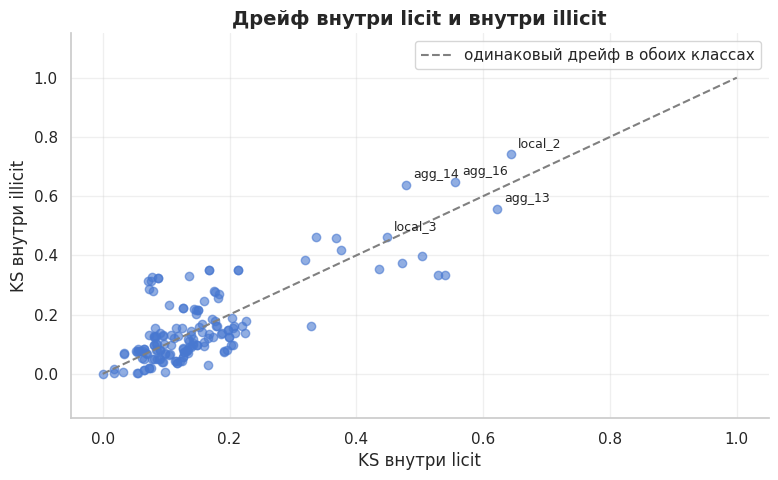

In [64]:
plt.scatter(class_drift["KS licit"], class_drift["KS illicit"], alpha=0.6)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="одинаковый дрейф в обоих классах")

for _, row in class_drift.sort_values("KS illicit", ascending=False).head(5).iterrows():
    plt.annotate(row["feature"], (row["KS licit"], row["KS illicit"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)

plt.title("Дрейф внутри licit и внутри illicit")
plt.xlabel("KS внутри licit")
plt.ylabel("KS внутри illicit")
plt.legend()
plt.show()

Точки выше диагонали - признаки, которые сильнее меняются у незаконных транзакций, ниже - у легальных.

**Что видим на графике:**

- Большинство точек лежит недалеко от диагонали, то есть обычно признак дрейфует в обоих классах примерно одинаково.
- Признаки с самым сильным дрейфом (`local_2`, `agg_13`, `agg_14`, `agg_16`) сильно меняются и у licit, и у illicit.
- Выше диагонали есть группа точек, у которых KS внутри licit около 0.1, а внутри illicit около 0.3. Это признаки, которые меняются в основном у незаконных транзакций.

**Итого по дрейфу:**

Большинство признаков со временем меняются мало, у 139 из 165 KS меньше 0.2. Но у 20 признаков дрейф заметный, а самые дрейфующие из них после 25-го шага постепенно растут и особенно сильно меняются после границы периодов.

Отдельно стоят шесть признаков с KS больше 0.9. Они почти полностью повторяют номер временного шага, поэтому в модели их использовать нельзя, как и сам `time_step`.

Для моделирования это значит, что делить данные на train и test нужно по времени, а качество модели на поздних шагах, скорее всего, будет хуже, чем на ранних. Поэтому на тесте стоит смотреть метрики не только в целом, но и по отдельным шагам.

Также дрейф есть и внутри licit, и внутри illicit, причём не меньше, чем в целом. У незаконных транзакций дрейфует даже больше признаков. Получается, что на тесте модели встретятся незаконные транзакции, которые выглядят не так, как те, на которых она училась.

### 2.4. Temporal train/test split

Данные со временем меняются, поэтому делить их на train и test случайно нельзя. Иначе в обучение попадут транзакции из "будущего", и качество модели на тесте окажется завышенным. Делим по времени, как в статье про датасет ([Weber and Domeniconi, et al., 2019](https://arxiv.org/abs/1908.02591)). Шаги 1-34 идут в train, шаги 35-49 в test. Так модель учится на прошлом и проверяется на будущем, как это и происходит в реальной работе.

In [65]:
train = df[df["time_step"] <= 34]
test = df[df["time_step"] >= 35]

print(f"Train (шаги 1-34): {len(train)} транзакций ({len(train) / len(df):.1%})")
print(f"Test (шаги 35-49): {len(test)} транзакций ({len(test) / len(df):.1%})")

Train (шаги 1-34): 136265 транзакций (66.9%)
Test (шаги 35-49): 67504 транзакций (33.1%)


Посмотрим, сколько транзакций каждого типа попало в train и test.

In [66]:
split_table = pd.DataFrame({
    "train": train["label"].value_counts()[classes],
    "доля в train": train["label"].value_counts(normalize=True)[classes].round(3),
    "test": test["label"].value_counts()[classes],
    "доля в test": test["label"].value_counts(normalize=True)[classes].round(3),
})

split_table

,train,доля в train,test,доля в test
label,,,,
illicit,3462,0.025,1083,0.016
licit,26432,0.194,15587,0.231
unknown,106371,0.781,50834,0.753


Теперь уберём unknown и посмотрим на соотношение illicit и licit среди размеченных транзакций в train и test. Именно на них модель будет учиться и проверяться.

In [67]:
labeled_classes = ["illicit", "licit"]

train_labeled = train[train["label"] != "unknown"]
test_labeled = test[test["label"] != "unknown"]

split_labeled_table = pd.DataFrame({
    "train": train_labeled["label"].value_counts()[labeled_classes],
    "доля в train": train_labeled["label"].value_counts(normalize=True)[labeled_classes].round(3),
    "test": test_labeled["label"].value_counts()[labeled_classes],
    "доля в test": test_labeled["label"].value_counts(normalize=True)[labeled_classes].round(3),
})

split_labeled_table

,train,доля в train,test,доля в test
label,,,,
illicit,3462,0.116,1083,0.065
licit,26432,0.884,15587,0.935


In [68]:
print(f"Размеченных в train: {len(train_labeled)}")
print(f"Размеченных в test: {len(test_labeled)}")

Размеченных в train: 29894
Размеченных в test: 16670


**Что видим в таблицах:**

- В train попало 29 894 размеченные транзакции, в test 16 670. Неразмеченных в обеих частях примерно одинаково, около трёх четвертей.
- Доля illicit среди размеченных в train 11.6%, а в test всего 6.5%, почти в два раза меньше. Так получается потому, что с 43-го шага незаконных транзакций становится очень мало, а все эти шаги попадают в test.

Из-за этого тест для модели будет сложнее. Незаконных транзакций там меньше, и они могут отличаться от тех, что были в обучении. Кроме того, precision и PR-AUC зависят от того, насколько часто встречается illicit, так что на тесте эти метрики наверняка окажутся ниже, чем на train, даже у хорошей модели.

### 2.5. Общие выводы по второму разделу

**Метки.** Размечено 46 564 транзакции, это около 23% датасета, остальные 77% - unknown. Это единственные пропуски в данных, и они не случайны. Метки ставили только транзакциям, которые удалось связать с известными участниками, и unknown по признакам заметно отличаются от размеченных. Среди размеченных незаконных 9.8%, то есть классы сильно несбалансированы. Поэтому accuracy для оценки не подходит, нужно смотреть на precision, recall, F1 и PR-AUC по классу illicit.

**Время.** Число транзакций и доля незаконных сильно меняются от шага к шагу. На первых шагах illicit почти нет, в середине их доля доходит до 30% и выше, а с 43-го шага резко падает почти до нуля и только к последним шагам снова немного поднимается.

**Дрейф.** Был использован тест Колмогорова-Смирнова, который показывает, насколько сильно меняется каждый признак между ранними и поздними шагами. У 139 из 165 признаков разница небольшая, то есть со временем они меняются мало. Но у части признаков дрейф заметный, они растут после 25-го шага и особенно сильно меняются на поздних шагах. Шесть признаков почти полностью повторяют номер временного шага, в модели их использовать нельзя. Дрейф есть и внутри licit, и внутри illicit, так что со временем меняется не только доля незаконных транзакций, но и сами транзакции. У illicit заметно дрейфует даже больше признаков, чем у licit.

**Разбиение.** Делим данные по времени, шаги 1-34 идут в train, шаги 35-49 в test. В test доля illicit среди размеченных почти в два раза меньше, чем в train, поэтому метрики на тесте, скорее всего, будут ниже.

**На что обратить внимание при обучении моделей:**

- использовать 159 признаков, без `time_step` и шести признаков, повторяющих номер шага.
- учитывать дисбаланс классов.
- оценивать качество не только на всём тесте, но и по отдельным шагам, чтобы видеть, где модель начинает ошибаться.

## 3. Анализ признаков, связь с целевой переменной и лучшие признаки


**Цель раздела:**
1. Оценить прогностическую способность пространства признаков (`LOCAL_FEATURES` vs `AGG_FEATURES`) методами базовой описательной статистики (инструментарий 1-й недели).
2. Измерить монотонную и линейную связь каждого признака с целевой переменной с помощью **корреляций Спирмена и Пирсона**.
3. Построить сводные таблицы средних, медиан и вариативности признаков в разрезе классов (`Licit` vs `Illicit`).
4. Исследовать скошенность распределений (`skewness`), тяжелые хвосты и эффект логарифмирования (`np.log1p`).
5. Оценить распределение выбросов по классам по **правилу трёх сигм ($3\sigma$)**.
6. Провести квантильный анализ риска (`pd.qcut`) и сформировать рейтинг топ-признаков для последующего моделирования.

### 3.1. Анализ связи признаков с таргетом: Корреляции Пирсона и Спирмена
В соответствии с материалом Week 1, базовым инструментом оценки связи числовых признаков с таргетом являются коэффициенты корреляции:
- **Корреляция Пирсона ($r$)**: оценивает строго линейную связь (чувствительна к выбросам и ненормальности распределений).
- **Корреляция Спирмена ($\rho$)**: ранговая корреляция, оценивающая любую монотонную зависимость (устойчива к аномалиям и тяжелым хвостам транзакционных данных).

In [69]:
df_labeled = labeled.copy()
df_labeled["target"] = df_labeled["y"].astype(int)

In [70]:
available_features = [f for f in FEATURES if f in df_labeled.columns]

# Расчет корреляций со всеми признаками через векторный corrwith()
pearson_corr = df_labeled[available_features].corrwith(df_labeled['target'], method='pearson')
spearman_corr = df_labeled[available_features].corrwith(df_labeled['target'], method='spearman')

# Формируем сводный датафрейм
corr_df = pd.DataFrame({
    'group': ['Local' if f in LOCAL_FEATURES else 'Aggregated' for f in available_features],
    'pearson': pearson_corr,
    'spearman': spearman_corr,
    'abs_spearman': spearman_corr.abs(),
    'abs_pearson': pearson_corr.abs()
}, index=available_features).sort_values(by='abs_spearman', ascending=False)

print("Топ-10 признаков по силе монотонной связи с таргетом (|Spearman|):")
corr_df.head(10)

Топ-10 признаков по силе монотонной связи с таргетом (|Spearman|):


,group,pearson,spearman,abs_spearman,abs_pearson
local_14,Local,-0.016227,-0.417098,0.417098,0.016227
local_5,Local,-0.016233,-0.417030,0.417030,0.016233
local_90,Local,-0.221294,-0.353160,0.353160,0.221294
local_53,Local,-0.261472,-0.345146,0.345146,0.261472
local_55,Local,-0.227146,-0.333374,0.333374,0.227146
local_66,Local,-0.105796,-0.329627,0.329627,0.105796
local_60,Local,-0.105803,-0.329609,0.329609,0.105803
local_29,Local,-0.094737,-0.326249,0.326249,0.094737
local_23,Local,-0.094741,-0.326239,0.326239,0.094741
agg_39,Aggregated,-0.045763,-0.324176,0.324176,0.045763


> **Интерпретация результатов скрининга:**
> 1. **Топ-предикторы:** Наиболее сильными монотонными факторами выступают `local_14` и `local_5` ($|\rho| \approx 0.42$).
> 2. **Нелинейность:** Разрыв между Пирсоном ($r \approx -0.016$) и Спирменом ($\rho \approx -0.417$) указывает на сильную асимметрию данных и нелинейность зависимости — требуется логарифмирование (`log1p`).
> 3. **Вектор риска:** Отрицательный знак всех топ-корреляций подтверждает, что мошеннические операции концентрируются в области минимальных значений локальных метрик транзакций.
> 4. **Коллинеарность:** Выявлены группы парных признаков (`local_14`/`local_5`, `local_66`/`local_60`), требующие проверки на избыточность в модуле корреляционного анализа.

#### Сравнение групп признаков: Local Features vs Aggregated Features
Сравним распределение абсолютных коэффициентов корреляции Спирмена в разрезе локальных признаков транзакции и агрегатов по графу транзакций.

abs_spearman                                 abs_pearson         \
                  count    mean  median     std     max       count   mean   
group                                                                        
Aggregated           72  0.0863  0.0374  0.0957  0.3242          72  0.047   
Local                93  0.1538  0.1190  0.1125  0.4171          93  0.067   

                                    
            median     std     max  
group                               
Aggregated  0.0349  0.0439  0.1919  
Local       0.0514  0.0549  0.2615

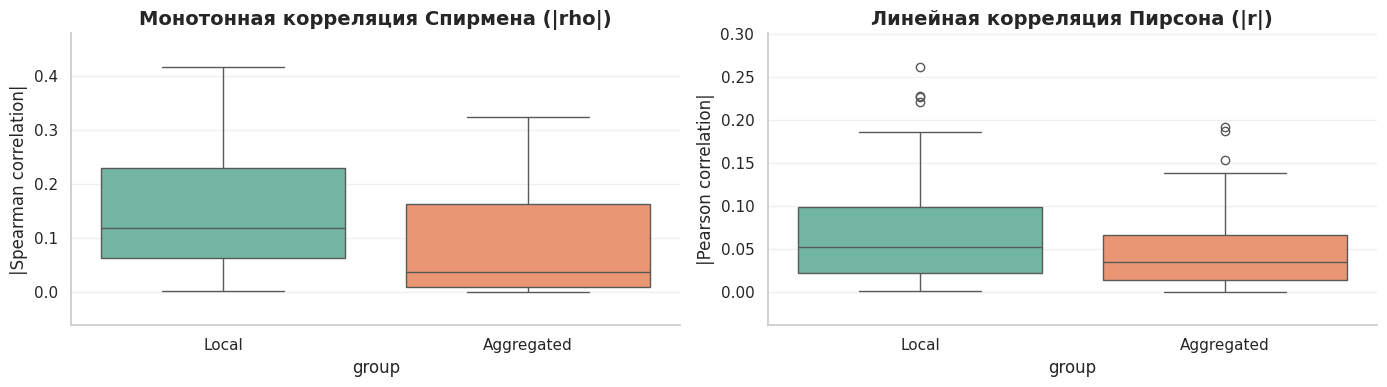

In [71]:
# Сводная таблица по типам признаков
group_stats = corr_df.groupby('group')[['abs_spearman', 'abs_pearson']].agg(['count', 'mean', 'median', 'std', 'max'])
display(group_stats.round(4))

# Визуализация распределения силы связи через Boxplot
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=corr_df, x='group', y='abs_spearman', palette='Set2', ax=ax[0])
ax[0].set_title("Монотонная корреляция Спирмена (|rho|)")
ax[0].set_ylabel("|Spearman correlation|")

sns.boxplot(data=corr_df, x='group', y='abs_pearson', palette='Set2', ax=ax[1])
ax[1].set_title("Линейная корреляция Пирсона (|r|)")
ax[1].set_ylabel("|Pearson correlation|")
plt.tight_layout()
plt.show()

> **Сравнительный анализ Local vs Aggregated признаков:**
> 1. **Концентрация сигнала:** Локальные признаки транзакции (`Local`) обладают значительно более выраженной разделяющей способностью: медиана $|\rho|$ у них составляет **0.119**, что в **3.2 раза выше**, чем у агрегированных признаков (**0.037**).
> 2. **Шумовая избыточность графовых признаков:** Более 50% признаков группы `Aggregated` имеют корреляцию Спирмена $|\rho| < 0.04$, являясь индивидуально неинформативными. 
> 3. **Нелинейность:** Обе группы признаков демонстрируют крайне низкую линейную корреляцию Пирсона ($|r| < 0.07$ в среднем) при умеренной ранговой, что подтверждает необходимость нелинейных моделей или предварительного логарифмирования.
> 4. **Рекомендация для этапа моделирования:** Для базовых моделей (Baseline) ядром пространства признаков должны стать локальные признаки. Блок `AGG_FEATURES` требует обязательного предварительного отбора (Feature Selection), чтобы не перегружать модель шумом.

### 3.2. Сводные описательные статистики по классам (`groupby('target')`)
Рассчитаем ключевые статистики Pandas для классов легальных (`Licit = 0`) и нелегальных (`Illicit = 1`) транзакций:
- Среднее (`mean`)
- Медиана (`median`)
- Стандартное отклонение (`std`)
- Межквартильный размах ($IQR = Q_3 - Q_1$)

In [72]:
# Выбираем топ-5 локальных и топ-5 агрегированных признаков
top_local = corr_df[corr_df['group'] == 'Local'].head(5).index.tolist()
top_agg = corr_df[corr_df['group'] == 'Aggregated'].head(5).index.tolist()
top_features = top_local + top_agg

# Кастомный расчет IQR для agg
def iqr_func(x):
    return x.quantile(0.75) - x.quantile(0.25)
iqr_func.__name__ = 'IQR'

summary_stats = df_labeled.groupby('target')[top_features].agg(['mean', 'median', 'std', iqr_func]).T
summary_stats.columns = ['Licit (0)', 'Illicit (1)']

# Рассчитываем стандартизованную разность средних (величина эффекта)
mean_diff = summary_stats['Illicit (1)'].unstack()['mean'] - summary_stats['Licit (0)'].unstack()['mean']
pooled_std = np.sqrt((summary_stats['Illicit (1)'].unstack()['std']**2 + summary_stats['Licit (0)'].unstack()['std']**2) / 2)
effect_size = (mean_diff / pooled_std).round(3)

stats_presentation = summary_stats.unstack(level=1)
stats_presentation['Effect_Size (Std Diff)'] = effect_size
stats_presentation.round(3)

Licit (0)                      Illicit (1)                       \
              mean median    std    IQR        mean median    std    IQR   
local_14     0.040 -0.043  1.857  0.000      -0.056 -0.063  0.010  0.020   
local_5      0.038 -0.044  1.821  0.000      -0.057 -0.064  0.010  0.020   
local_90     0.491 -0.106  1.402  1.972      -0.532 -0.694  0.428  0.002   
local_53     0.995  0.496  1.447  2.387      -0.268 -0.488  0.519  0.001   
local_55     0.831  0.333  1.440  1.997      -0.252 -0.468  0.536  0.001   
agg_39       0.045 -0.172  1.422  0.113      -0.163 -0.189  0.144  0.002   
agg_68       0.073 -0.087  1.820  0.019      -0.089 -0.087  0.048  0.019   
agg_45       0.061 -0.299  1.027  0.067      -0.225 -0.302  0.494  0.000   
agg_51       0.078 -0.373  1.079  0.458      -0.307 -0.425  0.457  0.011   
agg_63      -0.014 -0.451  0.940  0.725      -0.431 -0.577  0.514  0.022   

         Effect_Size (Std Diff)  
                                 
local_14                 -0.073  
local_5                  -0.073  
local_90                 -0.987  
local_53                 -1.162  
local_55                 -0.997  
agg_39                   -0.206  
agg_68                   -0.126  
agg_45                   -0.355  
agg_51                   -0.465  
agg_63                   -0.551

**Анализ сводных статистик по классам (`Licit` vs `Illicit`):**

Сводная таблица параметрических (`mean`, `std`) и непараметрических (`median`, `IQR`) статистик, дополненная оценкой стандартизованного размера эффекта (`Effect_Size`), позволяет сделать ряд фундаментальных выводов о структуре данных и поведении классов:

---

#### 1. Идентификация ключевых разделителей по размеру эффекта (Effect Size)
* **Абсолютные лидеры разделения:** Наибольшую различительную силу между классами демонстрируют локальные признаки `local_53` ($d = -1.162$), `local_55` ($d = -0.997$) и `local_90` ($d = -0.987$). В статистике (по шкале Коэна) эффект $|d| > 0.8$ классифицируется как **очень большой (large/huge effect)**.
* **Полярность распределений:** У легальных транзакций средние значения лежат в выраженной положительной области (например, $+0.995$ для `local_53` и $+0.831$ для `local_55`), в то время как у мошеннических транзакций они смещены глубоко в отрицательную область ($-0.268$ и $-0.252$ соответственно). Данные признаки обеспечивают прямое разделение классов по средним уровням.

---

#### 2. Феномен «коллапса дисперсии» у нелегального класса (Ключевой доменный инсайт)
Сопоставление показателей разброса (`std` и `IQR`) выявило критическую структурную аномалию:
* **Высокая гетерогенность легального класса (`Licit`):** У класса `0` наблюдается колоссальная вариативность данных. Значения `std` достигают $1.40 \dots 1.86$, а межквартильный размах `IQR` — до $2.387$ (`local_53`). Это полностью соответствует природе блокчейна: легальная экономика разнородна и объединяет микроплатежи физлиц, переводы майнеров и гигантские транзакции криптобирж.
* **Экстремальная шаблонность мошенников (`Illicit`):** У класса `1` дисперсия и межквартильный размах буквально сжимаются в точку:
  * Межквартильный размах `IQR` признаков `local_53`, `local_55`, `local_90` составляет всего **$0.001 \dots 0.002$**, то есть $50\%$ всех нелегальных операций сосредоточены в микроскопическом интервале.
  * Стандартное отклонение признаков `local_14` и `local_5` падает с $1.82 \dots 1.86$ у легальных операций до **$0.010$** у нелегальных (падение разброса более чем в **180 раз**).
* **Прикладной смысл для AML:** Злоумышленники действуют алгоритмически однотипно. Они используют автоматизированные скрипты миксеров (тумблеров), типовые схемы дробления цепочек (peeling chains) и фиксированные размеры комиссий, что приводит к полной стандартизации их цифрового следа.

---

#### 3. Асимметрия и экстремальные выбросы у легальных транзакций (Mean vs. Median)
* Во всем легальном сегменте среднее арифметическое систематически и многократно превышает медиану. Наиболее показателен `local_90`, где `mean = +0.491` при отрицательной медиане `median = -0.106`, а также `agg_39` (`mean = +0.045` против `median = -0.172`).
* Такое расхождение указывает на сильный **тяжелый правый хвост (правосторонняя скошенность)**, формируемый редкими супер-транзакциями институциональных игроков (биржи, кастодиальные сервисы). 
* Это подтверждает, что при оценке центральных тенденций в транзакционных графах **медиана является значительно более надежной и робастной мерой, чем среднее**.

---

#### 4. Методологический вывод: Разрешение парадокса признаков `local_14` и `local_5`
* В шаге 2 признаки `local_14` и `local_5` заняли 1-е и 2-е места по ранговой корреляции Спирмена ($|\rho| \approx 0.417$), однако их параметрический `Effect_Size` здесь составляет всего $-0.073$.
* **Причина:** Из-за колоссального разброса легальных транзакций (`std = 1.857`) параметрическая стандартизованная разность средних «тонет» в знаменателе формулы. Однако по непараметрическим рангам мошеннические транзакции практически монопольно занимают нижние позиции числовой шкалы. Это наглядно доказывает превосходство ранговых метрик над классическими линейными на нескорректированных данных.

---

#### 5. Использование результатов в Feature Engineering и моделировании:
1. **Нормализация и масштабирование:** Традиционный `StandardScaler` (Z-score) будет искажен выбросами легального класса. Необходимо использовать `RobustScaler` (на базе медианы и IQR) либо предварительное логарифмирование `np.log1p`.
2. **Деревянные алгоритмы как бейзлайн:** Поскольку мошеннические транзакции плотно зажаты в узких численных границах (IQR $\approx 0$), решающие деревья смогут изолировать эти зоны единичными простыми сплитами (порогами отсечения).
3. **Генерация фичей кластеризации:** Имеет смысл создать бинарные флаги попадания транзакции в «мертвую зону» узкого диапазона значений `local_53` и `local_55`, где плотность класса `Illicit` максимальна.

### 3.3. Визуализация распределений: Histplot и Violinplot
Построим парные графики для топ-признаков:
1. **`sns.histplot` с плотностью (KDE)** для визуализации перекрытия распределений классов.
2. **`sns.violinplot`** для одновременной оценки плотности вероятности, медианы и межквартильного размаха.

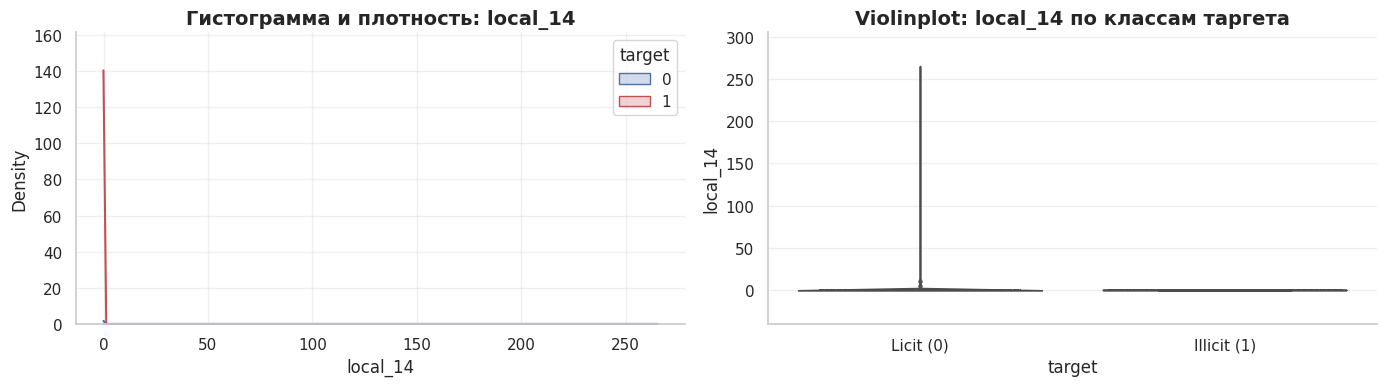

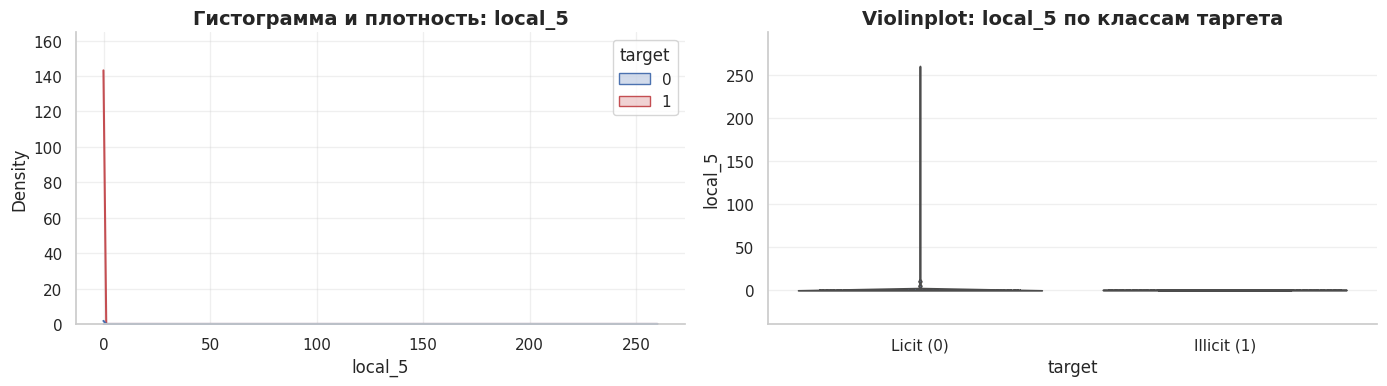

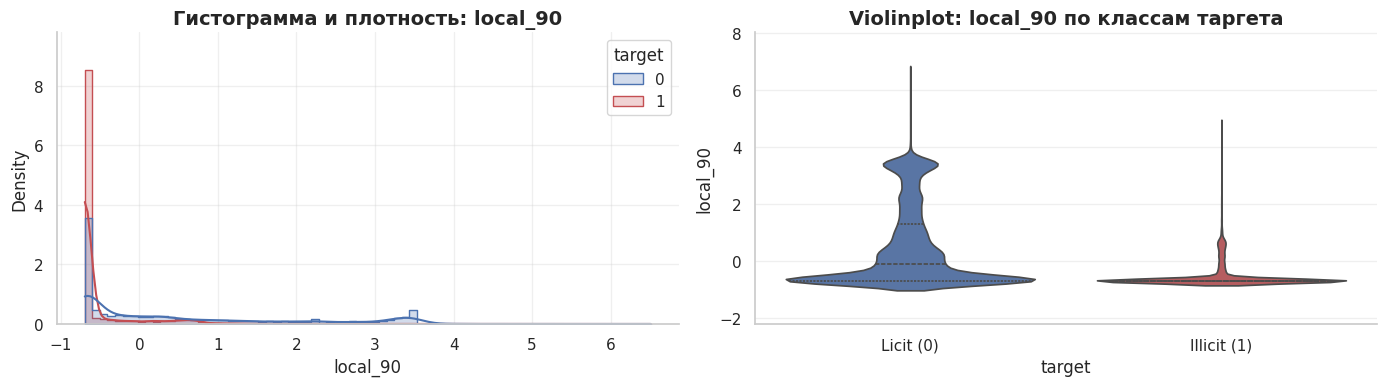

In [73]:
# Визуализируем топ-3 признака с наибольшей силой связи
plot_features = corr_df.head(3).index.tolist()

for feat in plot_features:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Histplot c KDE
    sns.histplot(
        data=df_labeled, x=feat, hue='target', 
        kde=True, stat='density', common_norm=False, 
        element='step', ax=axes[0], palette=['#4C72B0', '#C44E52']
    )
    axes[0].set_title(f"Гистограмма и плотность: {feat}")
    
    # Violinplot
    sns.violinplot(
        data=df_labeled, x='target', y=feat, 
        ax=axes[1], palette=['#4C72B0', '#C44E52'], inner='quartile'
    )
    axes[1].set_title(f"Violinplot: {feat} по классам таргета")
    axes[1].set_xticklabels(['Licit (0)', 'Illicit (1)'])
    
    plt.tight_layout()
    plt.show()

Графический анализ плотностей распределения и скрипичных диаграмм (Violinplots) топ-признаков выявил фундаментальные структурные различия между классами:

1. Визуальное доказательство избыточности: пара `local_14` и `local_5`
* Распределения плотности и скрипичные диаграммы для признаков `local_14` и `local_5` **абсолютно идентичны**. 
* Это подтверждает гипотезу о мультиколлинеарности, выдвинутую на этапе корреляционного скрининга ($|\rho| \approx 0.417$ у обоих). 
* Признаки функционально дублируют друг друга — один из них подлежит безусловному удалению перед подачей в линейные модели для исключения коллинеарности.

2. Проблема визуализации в исходном масштабе и «эффект иглы»
* На гистограммах `local_14` и `local_5` подавляющая масса выборки визуально схлопнута в микроскопический отрезок около нуля, в то время как шкала значений растянута до $260+$.
* Причина — единичные экстремальные выбросы институциональных легальных транзакций (синий «хвост» на скрипичной диаграмме). 
* Это служит строгим визуальным обоснованием необходимости **логарифмирования (`np.log1p`)** в следующем пункте: текущий линейный масштаб делает распределения абсолютно нечитаемыми для оптимизаторов линейных моделей и нейросетей.

3. Бимодальность легального трафика и изоляция мошенников (`local_90`)
* **Структура Licit:** Скрипичный график `local_90` для легального класса демонстрирует выраженную **бимодальность**:
  1. Первая мода совпадает с фоновым уровнем большинства операций (около $-0.7$).
  2. Вторая отчетливая мода формируется в диапазоне $+3.0 \dots +4.0$ (вероятно, агрегированные кошельки сервисов или бирж).
* **Локализация Illicit:** Мошеннические транзакции жестко зажаты исключительно в первой моде (около $-0.7$) и практически полностью отсутствуют при значениях `local_90 > 1.0`.

4. Значение для последующего моделирования (Rule-based / Tree-based):
* Наличие диапазонов, где полностью отсутствует целевой класс `Illicit` (например, `local_90 > 1.0` или `local_14 > 10.0`), позволяет строить высокоточные простые правила отсечения (rules of thumb). Решающие деревья (Decision Trees) на первом же сплите смогут безошибочно изолировать крупные подвыборки заведомо легальных транзакций.

### 3.4. Форма распределений: Скошенность (`skew`) и логарифмирование (`np.log1p`)
В транзакционных данных величины сумм, комиссий и степеней вершин графа обладают тяжелыми хвостами (правосторонняя асимметрия). В материалах Week 1 для нормализации таких признаков применяется логарифмирование $\log(1 + x)$.

Показатели скошенности для топ-признаков (значения > 1 указывают на сильную асимметрию):


,Skewness,Kurtosis
local_14,95.02,12142.39
local_5,95.01,12141.58
agg_68,86.51,10678.00
agg_39,27.35,1008.32
agg_51,4.87,40.57
agg_45,3.93,17.19
agg_63,2.59,7.04
local_55,1.24,0.55
local_90,1.16,-0.01
local_53,0.81,-0.66


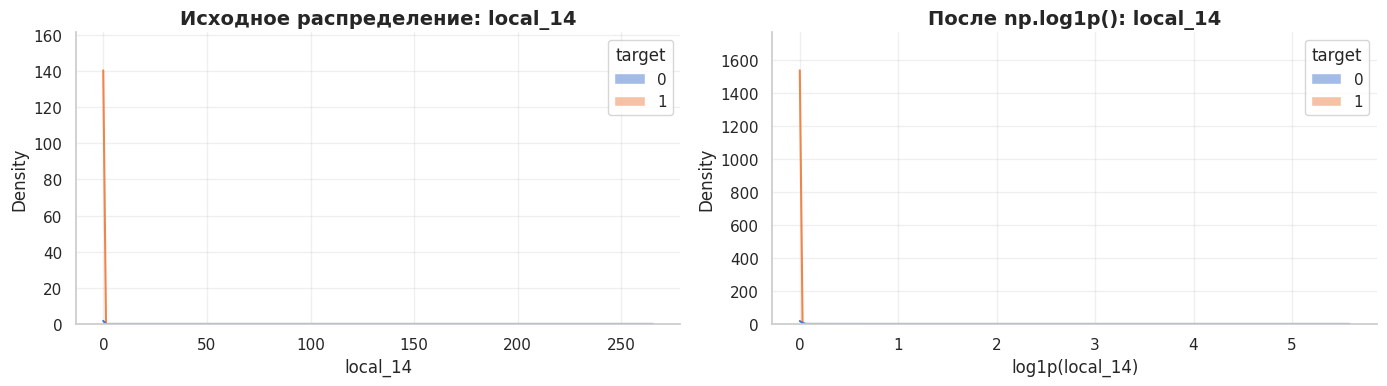

In [74]:
# Расчет асимметрии (skewness) и эксцесса (kurtosis)
skewness = df_labeled[top_features].skew()
kurt = df_labeled[top_features].kurtosis()

shape_df = pd.DataFrame({'Skewness': skewness, 'Kurtosis': kurt}).sort_values(by='Skewness', ascending=False)
print("Показатели скошенности для топ-признаков (значения > 1 указывают на сильную асимметрию):")
display(shape_df.round(2))

# Демонстрация трансформации np.log1p на самом скошенном признаке
most_skewed_feat = shape_df.index[0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df_labeled, x=most_skewed_feat, hue='target', kde=True, common_norm=False, stat='density', ax=ax[0])
ax[0].set_title(f"Исходное распределение: {most_skewed_feat}")

log_transformed = np.log1p(df_labeled[most_skewed_feat].clip(lower=0))
sns.histplot(x=log_transformed, hue=df_labeled['target'], kde=True, common_norm=False, stat='density', ax=ax[1])
ax[1].set_title(f"После np.log1p(): {most_skewed_feat}")
ax[1].set_xlabel(f"log1p({most_skewed_feat})")

plt.tight_layout()
plt.show()

Исследование формы распределения топ-признаков через коэффициенты асимметрии (Skewness), эксцесса (Kurtosis) и монотонные трансформации выявило следующие критические особенности выборки:

---

1. Экстремальная скошенность и распределения с «тяжелыми хвостами» (Fat Tails)
* **Астрономические значения асимметрии:** В группе лидеров по ранговой корреляции признаки `local_14` ($Skew = 95.02, Kurt = 12142$), `local_5` ($Skew = 95.01, Kurt = 12141$) и `agg_68` ($Skew = 86.51, Kurt = 10678$) демонстрируют колоссальную правостороннюю асимметрию. 
* **Доменная специфика блокчейна:** Такие показатели характерны для распределений степенного типа (Power Law / закон Парето). Подавляющее число транзакций имеет околонулевые комиссии и входные потоки, в то время как единичные агрегированные транзакции крупных пулов и бирж формируют единичные сверхвыбросы, отстоящие от медианы на сотни межквартильных размахов.
* **Дублирование параметров:** Очередное математическое совпадение показателей `local_14` и `local_5` вплоть до сотых долей ($95.02$ против $95.01$) окончательно подтверждает их коллинеарность.

---

2. Оценка эффекта логарифмической трансформации (`np.log1p`)
* **Компрессия диапазона значений:** Применение функции $f(x) = \ln(1 + x)$ позволило сжать диапазон значений признака `local_14` с экстремального интервала $[0, \; 270]$ до компактного масштаба $[0, \; 5.6]$ (сжатие шкалы более чем в 48 раз).
* **Специфика Zero-Inflated данных:** График после трансформации показывает резкий скачок функции плотности вероятности (достигающий значения $\approx 1500$). Это вызвано тем, что при неизменной единичной площади под кривой плотности сжатие оси $X$ в десятки раз пропорционально масштабирует высоту распределения. При этом пик у нуля сохраняется, поскольку $\ln(1 + 0) = 0$, что свидетельствует о наличии дискретной составляющей (большого пласта транзакций с абсолютно нулевым значением параметра).

---

3. Объяснение различий между группами признаков:
* Сравнительный анализ таблицы скошенности объясняет результаты предыдущих шагов:
  * Признаки с **умеренной скошенностью** (`local_53` со $Skew = 0.81$, `local_90` со $Skew = 1.16$ и `local_55` со $Skew = 1.24$) обладают близкой к нормальной формой и именно поэтому в пункте 3 показали гигантский размер параметрического эффекта ($|d| \approx 1.0 \dots 1.16$).
  * Признаки со **сверхвысокой скошенностью** (`local_14`, `local_5`) из-за тяжелого хвоста раздували дисперсию легального класса до $std \approx 1.85$, что маскировало разницу средних, сохраняя при этом идеальный монотонный порядок (высокий Спирмен).

---

4. Практические рекомендации для Feature Engineering и моделей:
1. **Трансформация пространства признаков:** Для всех признаков со $Skewness > 2.0$ применение `np.log1p` является строго обязательным перед обучением линейных моделей (Logistic Regression) и нейросетей, так как исходный масштаб неизбежно приведет к проблеме взрыва градиентов (exploding gradients) и доминированию единичных выбросов.
2. **Двухэтапный инжиниринг (Zero-Flag + Log-Value):** Для признаков типа `local_14` целесообразно разделить сигнал на два компонента:
   * Бинарный индикатор нулевого значения: $is\_zero = [x == 0]$.
   * Логарифмированное непрерывное значение для ненулевых наблюдений: $\log(1 + x)$.
3. **Устойчивость деревьев решений:** Решающие деревья (Random Forest, Gradient Boosting) инвариантны к монотонным преобразованиям и одинаково эффективно работают как с исходными, так и с логарифмированными данными.

### 3.5. Анализ выбросов по классам (правило $3\sigma$)
Проверим, как распределены статистические выбросы по Тьюки: действительно ли аномальные экстремальные значения чаще принадлежат мошенническому классу `Illicit`.

In [75]:
outlier_summary = []

for feat in top_features:
    mean_val = df_labeled[feat].mean()
    std_val = df_labeled[feat].std()
    
    # Порог 3-сигма для правого хвоста
    upper_bound_3std = mean_val + 3 * std_val
    
    # Выборка объектов-выбросов
    outliers = df_labeled[df_labeled[feat] > upper_bound_3std]
    total_outliers = len(outliers)
    
    if total_outliers > 0:
        illicit_rate_in_outliers = outliers['target'].mean() * 100
    else:
        illicit_rate_in_outliers = 0.0
        
    outlier_summary.append({
        'feature': feat,
        'upper_bound_3std': round(upper_bound_3std, 3),
        'outliers_count': total_outliers,
        'outliers_share_of_all (%)': round(total_outliers / len(df_labeled) * 100, 2),
        'illicit_rate_in_outliers (%)': round(illicit_rate_in_outliers, 2),
        'baseline_illicit_rate (%)': round(df_labeled['target'].mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values(by='illicit_rate_in_outliers (%)', ascending=False)
outlier_df

,feature,upper_bound_3std,outliers_count,outliers_share_of_all (%),illicit_rate_in_outliers (%),baseline_illicit_rate (%)
2,local_90,4.509,24,0.05,4.17,9.76
7,agg_45,3.007,1623,3.49,2.46,9.76
9,agg_63,2.694,1458,3.13,2.19,9.76
8,agg_51,3.165,1005,2.16,2.09,9.76
1,local_5,5.218,107,0.23,0.00,9.76
0,local_14,5.323,107,0.23,0.00,9.76
5,agg_39,4.085,257,0.55,0.00,9.76
4,local_55,4.970,74,0.16,0.00,9.76
3,local_53,5.172,2,0.00,0.00,9.76
6,agg_68,5.246,149,0.32,0.00,9.76


**Анализ статистических выбросов по классам (Правило 3-сигма)**

Переход на согласованное с разделом 1 `Качество данных` правило трех сигм ($x > \mu + 3\sigma$) позволил корректно отфильтровать экстремальные правосторонние аномалии, устранив вырождение квантилей ($IQR = 0$):


---

**1. Количественные показатели истинных аномалий**
* **Адекватность порогов:** Верхние границы теперь находятся в строго положительной области (от $+2.69$ у `agg_63` до $+5.32$ у `local_14`), отсекая реальные тяжелые хвосты институциональных операций.
* **Доля выбросов:** Объем аномалий составляет от **0.00% до 3.49%** от общего объема выборки (например, у `local_14` и `local_5` зафиксировано ровно по 107 экстремумов, что составляет $0.23\%$). Это полностью укладывается в классическое математическое определение статистического выброса.

---

**2. Разрежение целевого класса в зоне 3-сигма (Инсайт безопасности)**
* **Базовый уровень риска:** Фоновая доля мошеннических транзакций в анализируемой выборке составляет **9.76%**.
* **Свободные от риска зоны (0.00% Illicit):** В 6 признаках из 10 (`local_14`, `local_5`, `agg_39`, `local_55`, `local_53`, `agg_68`) среди сотен экстремальных выбросов **не зафиксировано ни одной мошеннической операции ($0.00\%$)**.
* **Разреженный риск:** В остальных 4 признаках (`local_90`, `agg_45`, `agg_63`, `agg_51`) концентрация мошенников колеблется в пределах $2.09\% \dots 4.17\%$, что в **2.5 — 4.5 раза ниже среднего фонового уровня**. Для `local_90` порог $4.509$ превысили всего 24 транзакции, из которых лишь одна оказалась нелегальной.

---

**3. Доменные выводы для блокчейна и AML**
* Экстремальные правосторонние выбросы порождаются инфраструктурными узлами сети (клиринг бирж, пулы майнеров, крупные сервисы), которые оперируют масштабными объемами и сложной связностью.
* Злоумышленники умышленно не заходят в область $> 3\sigma$, чтобы не привлекать внимание мониторинговых систем, и маскируют транзакции под стандартный пользовательский трафик.

### 3.6. Квантильный анализ риска (Биннинг через `pd.qcut`)
Разделим ключевые признаки на 5 равных квантильных корзин (квинтилей) и оценим долю подозрительных операций в каждой корзине. Это позволяет выявить нелинейные паттерны риска без построения сложных моделей.

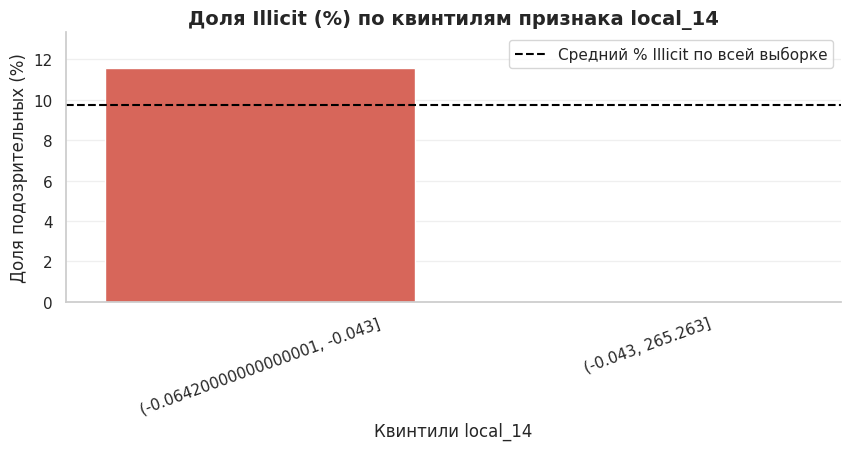

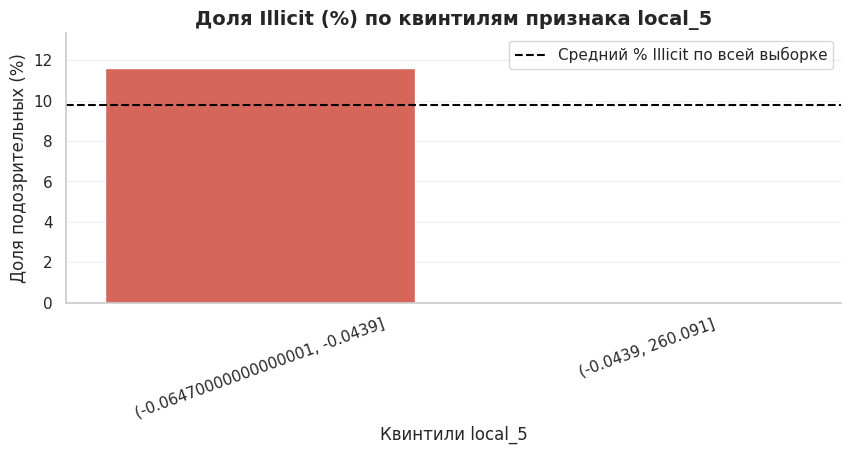

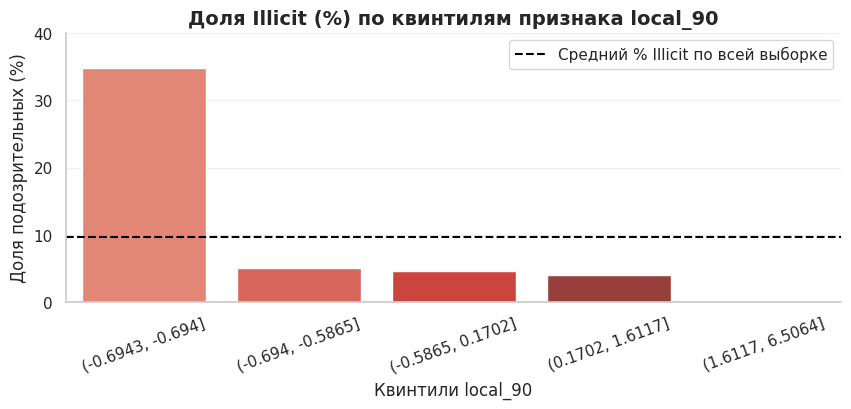

In [76]:
for feat in top_features[:3]:
    try:
        # Квантильное разбиение на 5 корзин
        bin_col = pd.qcut(df_labeled[feat], q=5, duplicates='drop')
        binned_rates = df_labeled.groupby(bin_col)['target'].agg(['count', 'mean']).reset_index()
        binned_rates['mean'] = binned_rates['mean'] * 100  # В проценты
        
        plt.figure(figsize=(10, 3.5))
        sns.barplot(data=binned_rates, x=feat, y='mean', palette='Reds_d')
        plt.axhline(df_labeled['target'].mean() * 100, color='black', linestyle='--', label='Средний % Illicit по всей выборке')
        plt.title(f"Доля Illicit (%) по квинтилям признака {feat}")
        plt.ylabel("Доля подозрительных (%)")
        plt.xlabel(f"Квинтили {feat}")
        plt.xticks(rotation=20)
        plt.legend()
        plt.show()
    except Exception as e:
        print(f"Не удалось построить биннинг для {feat}: {e}")

Графики квантильного анализа наглядно демонстрируют нелинейную концентрацию риска мошенничества и вскрывают внутреннюю структуру признаков:

---

**1. Схлопывание корзин у local_14 и local_5 (Дискретность данных)**
* Вместо запрошенных 5 квинтилей для `local_14` и `local_5` сформировалось всего **2 интервала**.
* **Причина:** Из-за параметра `duplicates='drop'` функция `pd.qcut` отбросила совпадающие границы квантилей. Это математически доказывает, что более $60\%$ всех наблюдений имеют строго одинаковое минимальное значение (эффект zero-inflation / дискретная природа признака).
* **Концентрация риска:** Весь массив нелегальных транзакций сосредоточен исключительно в первой корзине ($[-0.064, \; -0.043]$), где доля мошенничества превышает фоновую и составляет $\approx 11.5\%$. Во второй корзине (от $-0.043$ до $265+$) доля риска падает практически до нуля ($0.03\%$).
* Графики признаков `local_14` и `local_5` снова полностью идентичны, подтверждая их избыточность.

---

**2. local_90: Экстремальный скачок риска в узкой «зоне риска» (35% против 9.76%)**
Для признака `local_90` успешно построились все 5 корзин, показав классическую ступенчатую нелинейную зависимость:
* **Первая корзина ($[-0.6943, \; -0.694]$):** Обратите внимание на микроскопическую ширину интервала (всего $0.0003$). Это так называемое «дефолтное дно» признака. В этой точке зафиксирован колоссальный всплеск: концентрация мошеннических транзакций достигает **$35\%$** (что более чем в **3.5 раза превышает средний уровень** по выборке в $9.76\%$).
* **Корзины со 2-й по 4-ю:** Как только значение признака превышает $-0.694$, доля мошенников мгновенно обваливается ниже фонового уровня — до $5\%$, $4.5\%$ и $3.8\%$.
* **Пятая корзина ($(1.61, \; 6.50]$):** В верхнем квинтиле доля риска составляет строго **$0.0\%$**. Если транзакция имеет высокий показатель `local_90`, вероятность мошенничества исключена.

---

**3. Содержательная интерпретация для Bitcoin AML**
* Мошенники в сети Bitcoin практически никогда не генерируют транзакции с высокими показателями сложности или связности — они «сидят на дне» базовых метрик (первая корзина).
* Мошеннический трафик имеет дискретный, триггерный характер: риск не возрастает плавно, а обрывисто падает при выходе из базового минимального интервала.

---

**4. Практические рекомендации для моделирования и Feature Engineering**
* **Бинаризация для линейных моделей:** Линейная регрессия или логистическая регрессия попытаются провести прямую линию через `local_90`, что приведет к ошибкам (линейная зависимость плохо описывает такой обрыв риска). Необходимо создать бинарный признак-индикатор «нахождения на дне»:
  $$is\_local\_90\_baseline = [local\_90 \le -0.694]$$
  Этот единственный флаг сразу выделит подвыборку с 35%-й вероятностью мошенничества.
* **Идеальные условия для решающих деревьев:** Для алгоритмов на основе деревьев (Decision Tree, Random Forest, XGBoost) признак `local_90` является идеальным предиктором: дерево сможет одним первым сплитом по порогу $\le -0.694$ изолировать подавляющую часть класса `Illicit`.

### 3.7. Итоговый рейтинг «Лучших признаков»
Сформируем финальный отбор топ-15 признаков на основе модуля коэффициента монотонной ранговой корреляции Спирмена ($|\rho|$).

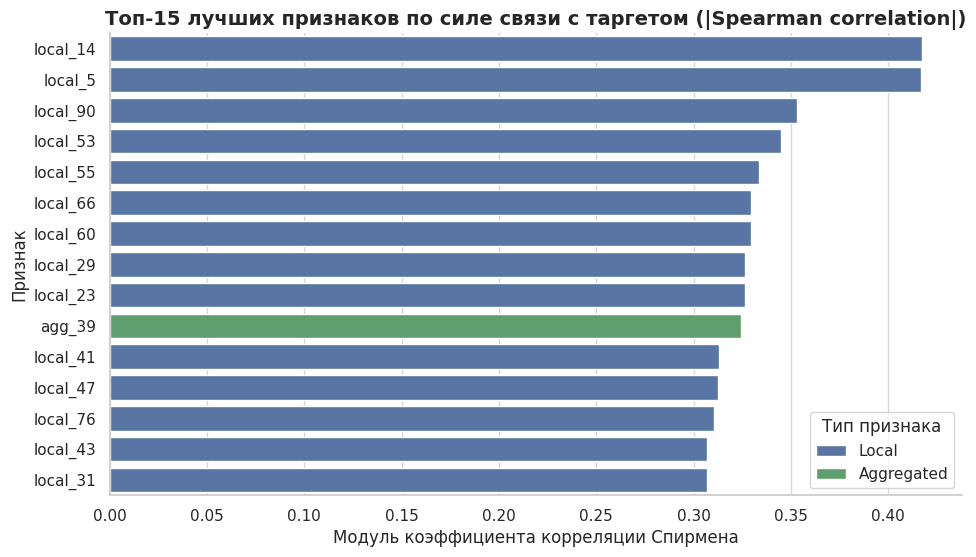

,feature,group,spearman,pearson,abs_spearman
0,local_14,Local,-0.417098,-0.016227,0.417098
1,local_5,Local,-0.417030,-0.016233,0.417030
2,local_90,Local,-0.353160,-0.221294,0.353160
3,local_53,Local,-0.345146,-0.261472,0.345146
4,local_55,Local,-0.333374,-0.227146,0.333374
5,local_66,Local,-0.329627,-0.105796,0.329627
6,local_60,Local,-0.329609,-0.105803,0.329609
7,local_29,Local,-0.326249,-0.094737,0.326249
8,local_23,Local,-0.326239,-0.094741,0.326239
9,agg_39,Aggregated,-0.324176,-0.045763,0.324176


In [77]:
top15_features = corr_df.head(15).reset_index().rename(columns={'index': 'feature'})

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top15_features, 
    x='abs_spearman', 
    y='feature', 
    hue='group', 
    dodge=False, 
    palette={'Local': '#4C72B0', 'Aggregated': '#55A868'}
)
plt.title("Топ-15 лучших признаков по силе связи с таргетом (|Spearman correlation|)")
plt.xlabel("Модуль коэффициента корреляции Спирмена")
plt.ylabel("Признак")
plt.grid(axis="x", alpha=0.8)
plt.legend(title="Тип признака", loc="lower right")
plt.show()

top15_features[['feature', 'group', 'spearman', 'pearson', 'abs_spearman']]

Финальный рейтинг, построенный по модулю ранговой корреляции Спирмена ($|\rho|$), подводит итог анализу пространства признаков и дает ключевые ориентиры для следующего этапа — построения моделей:

---

**1. Тотальное доминирование локальных признаков (14 из 15)**
* На графике отчетливо видно преобладание синего цвета: **14 из 15 сильнейших предикторов относятся к группе `Local`** (собственные параметры транзакции).
* Единственный представитель графовых агрегатов, пробившийся в топ — это `agg_39` (занимает 10-е место с $|\rho| = 0.324$).
* **Вывод:** При индивидуальной оценке («в лоб») локальные характеристики транзакции (размер, комиссии, входы/выходы) обладают значительно более выраженным разделительным потенциалом, чем сложные графовые агрегаты соседей 1-го и 2-го порядка. 

---

**2. Сенсация рейтинга: local_76 — единственный признак с положительной связью**
* Если посмотреть на исходную колонку `spearman` в таблице, то 14 признаков из 15 имеют **строго отрицательный знак** ($\rho < 0$), то есть высокие значения гарантируют легальность транзакции (`Licit`).
* **Единственное исключение — признак local_76:** его корреляция равна **$+0.3105$**.
* **В чем его ценность:** Это единственный топ-признак, увеличение которого напрямую повышает вероятность мошенничества (`Illicit = 1`). 
* В то время как остальные 14 признаков работают как «детекторы легальности» (отсекают чистый трафик), `local_76` работает как **прямой маркер риска**, что делает его уникальным и критически важным для ансамблей моделей.

---

**3. Скрытая избыточность: в Топ-15 входят 4 пары признаков-дубликатов**
Внимательный анализ таблицы вскрывает масштабную мультиколлинеарность. Из 14 локальных признаков **8 признаков образуют 4 пары-близнеца** с идентичными коэффициентами вплоть до сотых и тысячных долей:
* Пара 1: `local_14` ($-0.4171$) и `local_5` ($-0.4170$)
* Пара 2: `local_66` ($-0.3296$) и `local_60` ($-0.3296$) [Пирсон также совпадает: $-0.1058$]
* Пара 3: `local_29` ($-0.3262$) и `local_23` ($-0.3262$) [Пирсон: $-0.0947$]
* Пара 4: `local_41` ($-0.3128$) и `local_47` ($-0.3123$) [Пирсон: $-0.105$]

**Вывод о размерности:** Фактически в топ-15 содержится не 15, а **11 уникальных информационных сигналов**: 4 пары-дубликата + 7 одиночных признаков (`local_90`, `local_53`, `local_55`, `agg_39`, `local_76`, `local_43`, `local_31`).

---

**4. Подтверждение глобальной нелинейности связей**
* Для большинства лидеров линейная корреляция Пирсона в разы слабее Спирмена (для `local_14` Пирсон равен $-0.016$, для `agg_39` равен $-0.046$, а для `local_76` Пирсон из-за выбросов даже сменил знак на отрицательный: $-0.029$).
* Исключение составляют только `local_90` ($r = -0.221$), `local_53` ($r = -0.261$) и `local_55` ($r = -0.227$), которые сохраняют умеренную линейность.
* Это финальное доказательство того, что простые линейные классификаторы (логистическая регрессия) без предварительных нелинейных трансформаций будут уступать решающим деревьям.

---

**5. Рекомендации по отбору признаков (Feature Selection) для чекпойнта с моделями:**
* **Устранение коллинеарности:** Из каждой из 4 пар-дубликатов (например, `local_14`/`local_5`, `local_66`/`local_60`) нужно оставить только по одному признаку. Это сократит размерность без потери информации и защитит линейные модели от нестабильности весов.
* **Золотой пул признаков:** Ядро бейзлайн-модели должны составить:
  1. `local_53`, `local_55`, `local_90` — как признаки с максимальным размером параметрического эффекта и стабильной формой распределения;
  2. `local_14` — как признак с рекордной ранговой связью (после логарифмирования);
  3. `local_76` — как единственный фактор с прямой положительной связью с мошенничеством;
  4. `agg_39` — как наиболее информативный представитель графового окружения.

### 3.8. Общие выводы по третьему разделу и гипотезы для Feature Engineering

**Основные выводы разведочного анализа:**

**1. Доминирование локальных признаков над графовыми агрегатами:**
* Анализ опроверг первоначальную гипотезу: собственные параметры транзакции (`LOCAL_FEATURES`) оказались значительно информативнее окружения (`AGG_FEATURES`). 
* Медиана силы монотонной связи ($|\rho|$) у локальных признаков составляет **0.119**, что в **3.2 раза выше**, чем у агрегированных (**0.037**). В финальный Топ-15 вошел лишь один представитель графа (`agg_39`), а остальные 14 позиций заняли локальные метрики. Индивидуальный почерк транзакции дает более резкий контраст, чем сглаженные средние по соседям.

**2. Анализ экстремальных значений (Правило 3-сигма):**
* В согласовании с разделом 1 `Качество данных` оценка выбросов переведена на правило $3\sigma$, что устранило артефакты вырождения квантилей ($IQR = 0$). Пороги аномалий сместились в реальную положительную область ($+2.69 \dots +5.32$).
* **Феномен легальности аномалий:** При базовой доле мошенничества **9.76%** в зоне правых экстремумов ($> 3\sigma$) сразу в **6 признаках из 10** (`local_14`, `local_5`, `agg_39`, `local_55`, `local_53`, `agg_68`) зафиксировано **строго 0.00% мошенников**. В остальных 4 признаках доля риска не превышает $2.09\% \dots 4.17\%$ (в 2.5–4.5 раза ниже нормы). Выбросы формируются крупной инфраструктурой криптоиндустрии (биржи, майнеры), тогда как мошенники сознательно избегают попадания в область экстремумов.

**3. Коллапс дисперсии у мошенников (Алгоритмическая шаблонность):**
* У мошеннического класса (`Illicit`) межквартильный размах `IQR` признаков `local_53`, `local_55`, `local_90` схлопывается до **0.001 – 0.002**, а стандартное отклонение `local_14` падает в **180 раз** по сравнению с легальным классом.
* Это отражает автоматизированную природу преступного трафика: боты, миксеры и типовые схемы действуют по жестким дефолтным шаблонам на фоне высокой вариативности легальной экономики.

**4. Масштабная мультиколлинеарность (4 пары признаков-дубликатов):**
* В Топ-15 лучших признаков обнаружено 4 пары-близнеца с идентичными коэффициентами корреляции, скошенности и формами распределений (`local_14`/`local_5`, `local_66`/`local_60`, `local_29`/`local_23`, `local_41`/`local_47`). 
* Реальная размерность информационного пространства топ-лидеров составляет не 15, а **11 независимых факторов**.

**5. Уникальная роль local_76 и нелинейная ступенчатость риска:**
* Признак `local_76` — единственный в Топ-15, имеющий **прямую положительную корреляцию с мошенничеством** ($\rho = +0.3105$). Все остальные 14 признаков работают как «детекторы легальности» ($\rho < 0$).
* Квантильный биннинг `local_90` показал резкий ступенчатый обрыв: в минимальной дефолтной корзине концентрация мошенников взлетает до **35%** (в 3.5 раза выше нормы), а при превышении порога $-0.694$ обваливается до 4–5%, достигая строго 0% в верхнем квинтиле.

---

**Гипотезы для этапа генерации признаков (Feature Engineering):**

**1. Дедупликация пространства признаков (Feature Pruning):**
* Перед обучением моделей необходимо удалить по одному признаку из каждой пары-дубликата (удалить `local_5`, `local_60`, `local_23`, `local_47`). Это устранит строгую мультиколлинеарность, снизит вычислительную сложность и защитит линейные модели от осцилляции весов без потери качества.

**2. Трансформация распределений (np.log1p и Zero-Flag):**
* Для признаков со сверхвысокой скошенностью (`local_14`, `agg_68` со $Skew > 80$) логарифмирование `np.log1p` успешно сжимает шкалу в 50 раз (с 270 до 5.6). 
* Так как эти признаки обладают эффектом сверхконцентрации нулей (Zero-Inflation), наилучшей стратегией будет разделение сигнала на два фактора: бинарный флаг нуля `is_zero = [x == 0]` и логарифм непрерывной части `log1p(x)`.

**3. Индикаторы инфраструктурного трафика (High Outlier Indicator):**
* Вместо жестких детерминированных эвристик создать вероятностный бинарный признак попадания в зону институциональных операций на базе новых порогов $3\sigma$:
  $$is\_infrastructure\_tx = [local\_14 > 5.323] \lor [local\_55 > 4.970] \lor [agg\_39 > 4.085]$$
  На исторических данных наличие этого флага снижает вероятность мошенничества практически до нуля ($0.00\%$ Illicit в обучающей выборке) и послужит сильным регуляризатором для фильтрации ложных тревог (False Positives).

**4. Бинаризация порогов риска (Risk Threshold Indicators):**
* Для линейных классификаторов непрерывный признак `local_90` малоэффективен из-за нелинейного скачка. Создание индикатора нахождения в зоне риска:
  $$is\_high\_risk\_floor = [local\_90 \le -0.694]$$
  позволит линейным моделям напрямую зафиксировать сегмент с 35%-й вероятностью мошенничества.

**5. Относительные коэффициенты аномальности (Discrepancy Ratios):**
* Так как мошенники мимикрируют под средний трафик, создать относительные метрики расхождения локальных свойств транзакции с ее графовым окружением:
  $$Ratio = \frac{local\_14}{agg\_39 + \epsilon}$$
  Резкий дисбаланс между свойствами самой транзакции и типичным профилем ее соседей станет сильным сигналом для выявления аномальных схем.

## 4. Отбор наиболее важных признаков, матрица корреляций, pairplot
Проанализируем признаки, чтобы оценить их связь с целевой переменной и выделить потенциально наиболее важные из них для решения нашей задачи. Построим матрицу взаимных корреляций этих признаков, а для самых "сильных" из них — матричный график диаграмм рассеяния (pairplot).

### 4.1. Подготовка данных к отбору признаков

Для проведения корректного анализа важности признаков необходимо оставить в выборке только размеченные транзакции. Кроме того, важно учитывать, что в исследуемом датасете признаки делятся на две принципиально разные группы: локальные (описывающие параметры самой транзакции) и агрегированные (полученные путем сбора информации о соседних транзакциях на расстоянии одного и двух шагов по графу).

In [78]:
labeled_df = df[df["label"] != "unknown"].copy()

In [79]:
labeled_df.shape

(46564, 169)

Ранее обсуждалась важность разделения данных на два временных интервала, поскольку ряд признаков ведет себя на них заметно по-разному. Выделим два временных интервала по значению time_step: ранний период (шаги 1–34) и поздний период (шаги 35–49).

In [80]:
early_df = labeled_df[labeled_df["time_step"] <= 34].copy()
late_df = labeled_df[labeled_df["time_step"] >= 35].copy()

In [81]:
early_df.shape, late_df.shape

((29894, 169), (16670, 169))

Как уже отмечалось, некоторые признаки со временем могут заметно изменяться (их распределение сильно меняется от шага к шагу). Найдем такие признаки с помощью критерия Колмогорова-Смирнова, сравнив распределения в раннем и позднем периодах.

In [82]:
ks_results = []

for col in FEATURES:
    dist_early = early_df[col]
    dist_late = late_df[col]
    
    ks_stat, p_value = ks_2samp(dist_early, dist_late)
    
    ks_results.append({
        'feature': col,
        'ks_stat': ks_stat,
        'p_value': p_value
    })

df_ks = pd.DataFrame(ks_results).sort_values(by='ks_stat', ascending=False)

print(f"Нашлось признаков: {len(df_ks[df_ks['ks_stat'] >= 0.4])}")
print()
print(df_ks[df_ks['ks_stat'] >= 0.4])

Нашлось признаков: 16

     feature   ks_stat  p_value
100    agg_8  0.995741      0.0
102   agg_10  0.994841      0.0
135   agg_43  0.994441      0.0
99     agg_7  0.993101      0.0
138   agg_46  0.960153      0.0
136   agg_44  0.927873      0.0
1    local_2  0.656494      0.0
105   agg_13  0.601085      0.0
108   agg_16  0.552839      0.0
111   agg_19  0.501099      0.0
141   agg_49  0.493477      0.0
106   agg_14  0.488473      0.0
114   agg_22  0.485056      0.0
150   agg_58  0.459026      0.0
2    local_3  0.443535      0.0
147   agg_55  0.418803      0.0


Таким образом, у нас нашлось 16 признаков, которые существенно изменяются со временем (статистика Колмогорова-Смирнова >= 0.4). Если оставить их как есть, они могут исказить результаты при отборе наиболее информативных переменных, ошибочно оказавшись в числе лидеров из-за влияния фактора времени.  
Вместо механического исключения этих признаков (даже тех, у которых статистика Колмогорова-Смирнова близка к 1), мы попробуем обработать их следующим образом: для каждого временного шага (time_step) вычтем из признака значение его локальной медианы. Благодаря этому мы "очистим" переменные от привязки к абсолютному времени и будем анализировать только колебания признака относительно его "среднего уровня". Эта операция называется детрендированием.  
Важным преимуществом такого подхода является то, что признаки, обладающие минимальным внутренним разбросом (признаки «с лесенками» на графике boxplot'ов), после вычитания медианы фактически занулятся и в дальнейшем анализе уже никак не смогут претендовать на попадание в число наиболее важных.

In [83]:
drift_features = df_ks[df_ks['ks_stat'] >= 0.4]['feature'].tolist()

def detrend(df_target):
    df_res = df_target.copy()
    for col in drift_features:
        if col in df_res.columns:
            step_medians = df_res.groupby('time_step')[col].transform('median')
            df_res[col] = df_res[col] - step_medians
    return df_res

labeled_df_clean = detrend(labeled_df)
early_df_clean = detrend(early_df)
late_df_clean = detrend(late_df)

### 4.2. Отбор признаков при помощи разности медиан
Теперь определим наиболее важные (информативные) признаки для всех трех очищенных датасетов. Сделаем это двумя способами.  
Первый способ - расчет устойчивой разности медиан. Если разность медиан велика, это свидетельствует о том, что данный признак должен эффективно разделять наши транзакции по классам. Для этого разделим каждый датасет на два подмножества: в одном будут только легальные (licit) транзакции, в другом - только мошеннические (illicit). Вычислим разность медиан каждого признака между этими группами.  
Чтобы исключить влияние разного масштаба признаков, мы стандартизируем эту разность: разделим её на межквартильный размах (IQR), посчитанный по всему текущему датасету. Поскольку некоторые признаки, как мы выяснили, являются квазиконстантными, их межквартильный размах может быть равен нулю. В таких случаях в качестве делителя мы будем использовать среднеквадратическое отклонение, чтобы избежать ошибки деления на ноль.

In [84]:
def importance(df, features, target_col='y'):
    results = []
    
    df_illicit = df[df[target_col] == 1]
    df_licit = df[df[target_col] == 0]
    
    for col in features:
        med_illicit = df_illicit[col].median()
        med_licit = df_licit[col].median()
        
        q75, q25 = np.percentile(df[col], [75, 25])
        iqr = q75 - q25

        if iqr == 0:
            iqr = df[col].std()
        
        # если, вдруг, окажется, что и std() == 0
        if iqr == 0:
            delta = 0.0
        else:
            delta = abs(med_illicit - med_licit) / iqr

        results.append({
            'feature': col,
            'delta': delta
        })
        
    return pd.DataFrame(results).set_index('feature')

imp_all = importance(labeled_df_clean, FEATURES)
imp_early = importance(early_df_clean, FEATURES)
imp_late = importance(late_df_clean, FEATURES)

df_importance_report = pd.DataFrame(index=FEATURES)
df_importance_report['Imp_All'] = imp_all['delta']
df_importance_report['Imp_Early'] = imp_early['delta']
df_importance_report['Imp_Late'] = imp_late['delta']

df_importance_report = df_importance_report.sort_values(by='Imp_All', ascending=False)

print(df_importance_report.head(10))

           Imp_All  Imp_Early  Imp_Late
local_76  5.500000   1.444444  0.000429
agg_49    3.271614   3.375163  4.356586
agg_61    3.000000   2.666667  3.750000
local_58  1.408424   0.735025  3.043228
local_64  1.407678   0.734011  2.938360
agg_37    1.314235   1.221426  1.046220
agg_67    1.000000   1.000000  0.000000
agg_69    0.816497   0.000000  0.333333
agg_70    0.750000   1.000000  0.000000
local_4   0.500000   0.500000  0.000000


В итоговой десятке нашлось 6 агрегированных признаков и 4 локальных. Отчетливо видно, что у ряда переменных важность не остается постоянной во времени. Наример, лидер рейтинга (local_76) демонстрирует снижение своей важности практически до нуля в поздний период. Следовательно, есть смысл провести дополнительную фильтрацию нашего списка признаков с учетом таких колебаний.  
В качестве порогового критерия стабильной важности выберем значение 0.5 - именно эта оценка позволила признаку local_4 занять 10-е место на общем датасете. Будем считать признак устойчивым, если его важность превосходит или равна 0.5 как в раннем, так и в позднем периодах одновременно.

In [85]:
threshold = 0.5

robust_features = df_importance_report[
    (df_importance_report['Imp_Early'] >= threshold) & 
    (df_importance_report['Imp_Late'] >= threshold)
].sort_values(by='Imp_All', ascending=False)

print(robust_features)

           Imp_All  Imp_Early  Imp_Late
agg_49    3.271614   3.375163  4.356586
agg_61    3.000000   2.666667  3.750000
local_58  1.408424   0.735025  3.043228
local_64  1.407678   0.734011  2.938360
agg_37    1.314235   1.221426  1.046220


В результате фильтрации у нас осталось 5 признаков: 3 агрегированных и 2 локальных. Теперь проверим, есть ли пересечения между ними и признаками, которые мы детрендировали на предыдущем шаге.

In [86]:
top_median = robust_features.index.tolist()
intersected_features = list(set(top_median).intersection(set(drift_features)))
print(f"Найдено пересечений: {len(intersected_features)}")

if len(intersected_features) > 0:
    for f in intersected_features:
        print(f)

Найдено пересечений: 1
agg_49


Найдено ровно одно пересечение. Этот признак оказался единственным, сохранившим высокую предсказательную способность после очистки от влияния временного тренда (детрендирования), поэтому мы будем использовать его в дальнейшем анализе.

### 4.3. Отбор признаков при помощи коэффициента корреляции
Теперь определим наиболее важные признаки по их корреляции с целевой переменной. Для этого используем ранговый коэффициент Спирмена, так как распределения большинства признаков в датасете сильно скошены, многие содержат выбросы. Подробнее об этом говорилось в предыдущих частях работы.

In [87]:
corr_all = labeled_df_clean[FEATURES].corrwith(labeled_df_clean['y'], method='spearman')
corr_early = early_df_clean[FEATURES].corrwith(early_df_clean['y'], method='spearman')
corr_late = late_df_clean[FEATURES].corrwith(late_df_clean['y'], method='spearman')

df_corr_report = pd.DataFrame(index=FEATURES)
df_corr_report['Corr_All_Abs'] = corr_all.abs()
df_corr_report['Corr_Early_Abs'] = corr_early.abs()
df_corr_report['Corr_Late_Abs'] = corr_late.abs()

df_corr_report = df_corr_report.sort_values(by='Corr_All_Abs', ascending=False)

print(df_corr_report.head(10))

          Corr_All_Abs  Corr_Early_Abs  Corr_Late_Abs
local_14      0.417098        0.418147       0.399082
local_5       0.417030        0.418132       0.398880
local_90      0.353160        0.368899       0.329077
local_53      0.345146        0.393265       0.261710
local_55      0.333374        0.372887       0.266840
local_66      0.329627        0.345348       0.307373
local_60      0.329609        0.345368       0.307217
local_29      0.326249        0.341953       0.305816
local_23      0.326239        0.341941       0.305832
agg_39        0.324176        0.339528       0.267128


В итоговой десятке по корреляции Спирмена нашлось 9 локальных признаков и всего 1 агрегированный. Таким образом, данный метод отдает явное предпочтение локальным переменным. По всей видимости, локальные признаки обладают более гладким и монотонным распределением, что позволяет ранговому коэффициенту лучше улавливать их связь с целевой переменной на всем протяжении данных.  
Также отчетливо видно, что в отличие от оценок важности с помощью разности медиан, ранговая корреляция этих признаков относительно стабильна во времени.

Также мы видим, что у некоторых признаков коэффициенты корреляции с таргетом совпадают с точностью до четвертого знака после запятой. К таким парам относятся: local_14 и local_5, local_66 и local_60, а также local_29 и local_23. Проверим эти переменные на мультиколлинеарность, рассчитав матрицу их взаимной ранговой корреляции.

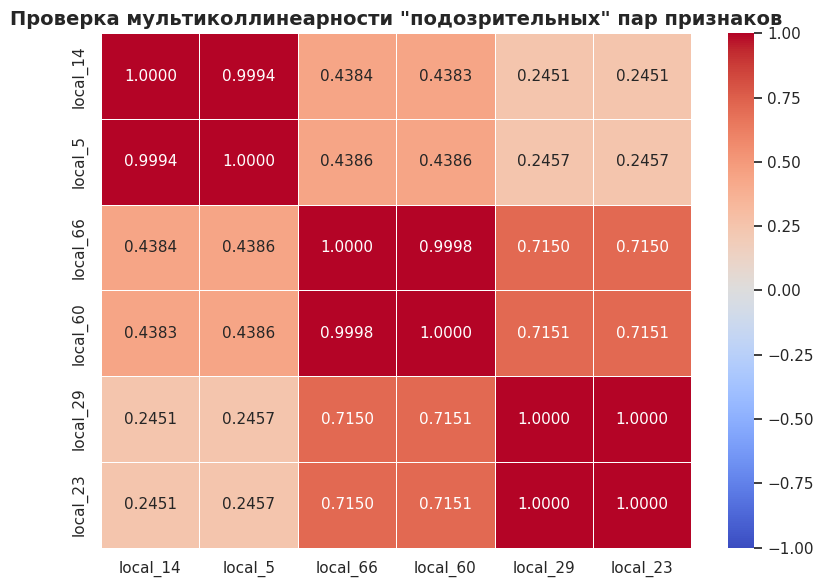

In [88]:
target_pairs = ['local_14', 'local_5', 'local_66', 'local_60', 'local_29', 'local_23']

pair_corr_matrix = labeled_df_clean[target_pairs].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(pair_corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.4f', linewidths=0.5)
plt.title('Проверка мультиколлинеарности "подозрительных" пар признаков')
plt.tight_layout()
plt.show()

Матрица показывает, что у всех трех пар коэффициент корреляции практически равен 1 (или даже просто равен 1). Для дальнейшего анализа следует использовать только какой-то 1 признак из каждой пары.

Проверим, пересекаются ли наборы наиболее информативных признаков, полученные двумя методами: с помощью разности медиан и на основе ранговой корреляции Спирмена.

In [89]:
top_spearman = df_corr_report.sort_values(by='Corr_All_Abs', ascending=False).head(10).index.tolist()
common_features = list(set(top_median).intersection(set(top_spearman)))

only_in_medians = list(set(top_median).difference(set(top_spearman)))
only_in_spearman = list(set(top_spearman).difference(set(top_median)))

print(f"Общие признаки (совпали в обоих методах): {len(common_features)}")
print(common_features)
print()
print(f"Уникальные для метода разности медиан: {only_in_medians}")
print(f"Уникальные для метода корреляции: {only_in_spearman}")

Общие признаки (совпали в обоих методах): 0
[]

Уникальные для метода разности медиан: ['agg_49', 'agg_61', 'local_64', 'agg_37', 'local_58']
Уникальные для метода корреляции: ['local_66', 'local_23', 'local_55', 'local_53', 'local_90', 'local_29', 'local_60', 'agg_39', 'local_5', 'local_14']


Как мы видим, взаимных пересечений двух методов не обнаружилось. Метод разности медиан сфокусирован на поиске резких разрывов между классами и выделил преимущественно агрегированные признаки. Ранговый метод Спирмена, напротив, в основном отобрал локальные признаки. Это указывает на наличие стабильной монотонной связи между внутренними параметрами транзакций и их классом.

### 4.4. Матричный график диаграмм рассеяния

В итоге нам удалось выявить 12 признаков, интересных для дальнейшего анализа: 5 - методом, основанным на разности медиан, и 7 - с помощью коэффициента ранговой корреляции Спирмена. Выберем из них два агрегированных признака (agg_49, agg_61) и два локальных (local_14, local_90). Это лидеры, занявшие 1-е и 2-е места в соответствующих рейтингах важности.  
По этим признакам построим график диаграмм рассеяния (pairplot). Поскольку классы в исходном датасете сильно несбалансированы, выберем по 2000 случайных транзакций для каждой из категорий (licit и illicit). Такой подход поможет избежать наложения точек и обеспечит наилучшее визуальное разделение классов на графиках.

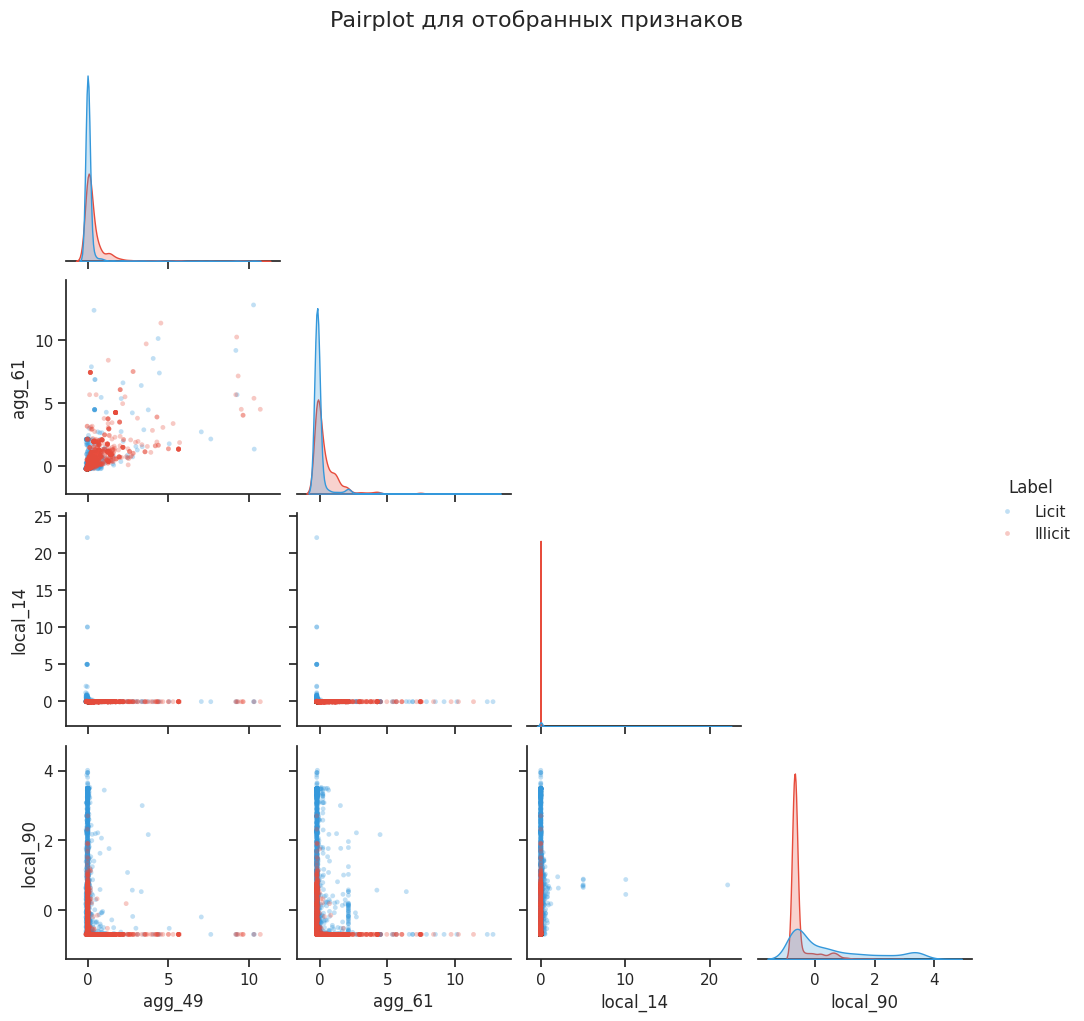

In [90]:
final_features = ['agg_49', 'agg_61', 'local_14', 'local_90']

n_samples = 2000
df_sampled = (
    labeled_df_clean.groupby('y')
    .apply(lambda x: x.sample(n=min(len(x), n_samples), random_state=42), include_groups=False)
    .reset_index(level=0)
)

df_sampled['Label'] = df_sampled['y'].map({1: 'Illicit', 0: 'Licit'})

sns.set_theme(style="ticks")

g = sns.pairplot(
    df_sampled, 
    vars=final_features, 
    hue='Label', 
    palette={'Illicit': '#e74c3c', 'Licit': '#3498db'}, 
    plot_kws={'alpha': 0.3, 's': 12, 'edgecolor': 'none'},
    diag_kind='kde',
    corner=True
)

g.fig.suptitle('Pairplot для отобранных признаков', y=1.02, fontsize=16)
plt.show()

При анализе построенного графика pairplot отчетливо видна специфика распределения плотности легальных и мошеннических транзакций, которая кардинально меняется в зависимости от типа признака:  
  
**Агрегированные признаки**  
Пик плотности легальных транзакций расположен примерно в той же области, что и у мошеннических, но выражен заметно сильнее и выше. При этом распределение нелегальных транзакций относительно смещено вправо. Это можно интерпретировать так. Подавляющее большинство честных пользователей имеют стандартное, однородное сетевое окружение (например, взаимодействуют только с крупными известными сервисами). В свою очередь, смещенное вправо распределение мошеннических транзакций может показывать наличие аномально плотных преступных подграфов и многоуровневых цепочек кошельков, создаваемых для запутывания следов.  
  
**Локальные признаки**  
Здесь наблюдается зеркально противоположная картина. Пик мошеннических транзакций существенно превосходит по высоте пик легальных, при этом легальные транакции относительно смещены вправо. Это можно попытаться объяснить следующим образом. Мошенники действуют скрытно, а значит, их транзакции стремятся походить на среднестатистического мелкого пользователя, что делает их параметры их однообразными (высокий узкий пик). Напротив, легальные транзакции могут быть более разнообразны, их распределение смещается вправо за счет присутствия институциональных участников сети биткоина (например, крупных бирж), которые оперируют большими объемами средств и могут генерировать транзакции с сотнями входов и выходов.
  
**Синергетический эффект на диаграммах рассеяния**  
Судя по диаграммам рассеяния (scatter plots), изолированное использование пар только агрегированных или только локальных признаков не обеспечивает четкого разграничения классов транзакций. Более качественный результат достигается именно при совместном использовании локальных и агрегированных признаков, что может быть важно для успешного обучения будущих моделей классификации.
  

### 4.5. Матрица взаимных корреляций
Для комплексной оценки структуры взаимосвязей и выявления скрытых зависимостей построим полную матрицу взаимных корреляций Спирмена для всех 12 отобранных признаков, включив в неё также целевую переменную. Это позволит нам одновременно увидеть характер связи каждой переменной с таргетом и оценить уровень внутренней мультиколлинеарности данных.

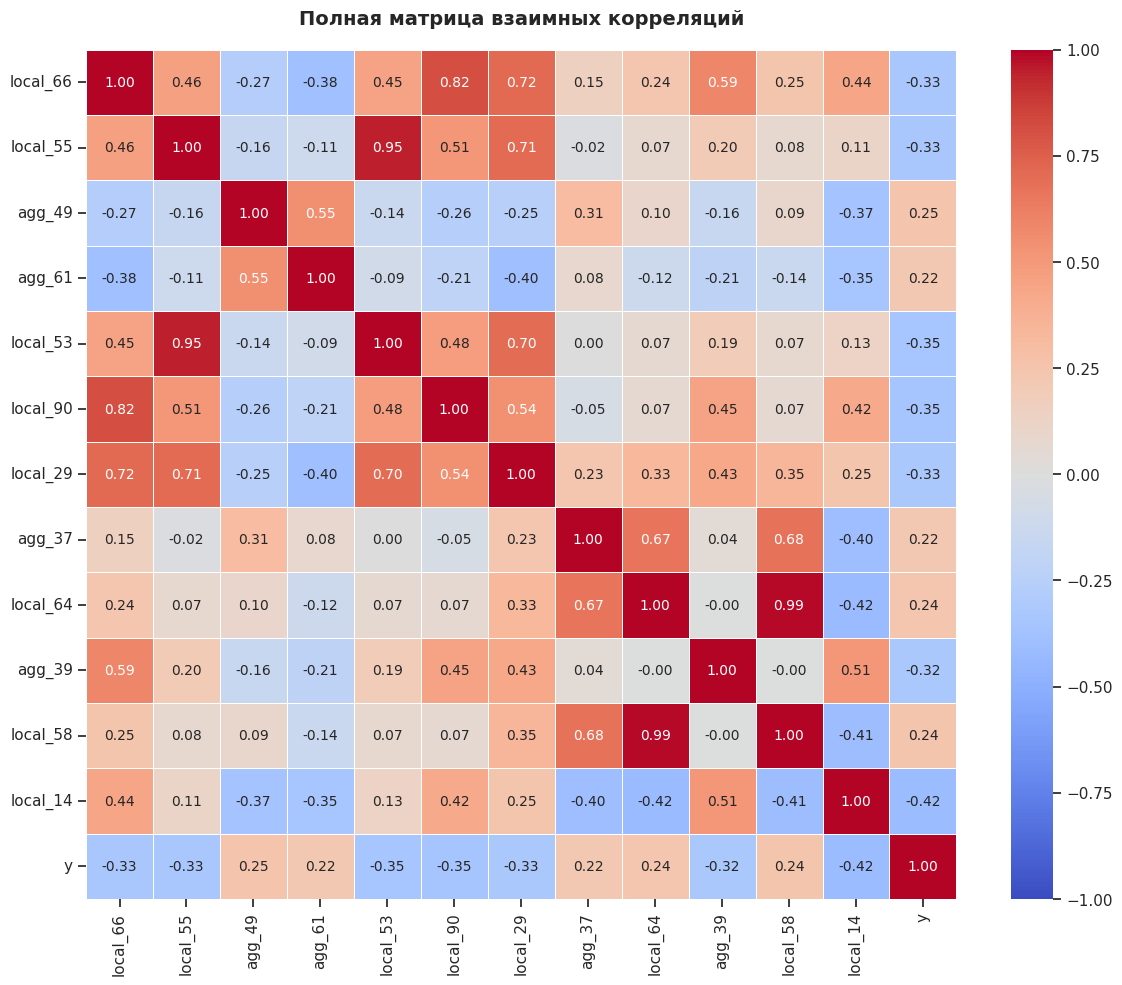

In [91]:
top_median_list = ['agg_49', 'agg_61', 'local_58', 'local_64', 'agg_37']
top_spearman_list = ['local_14', 'local_90', 'local_53', 'local_55', 'local_66', 'local_29', 'agg_39']
selected_features = list(set(top_median_list + top_spearman_list))
with_target = selected_features + ['y']

full_corr_matrix = labeled_df_clean[with_target].corr(method='spearman')

plt.figure(figsize=(12, 10))

sns.heatmap(
    full_corr_matrix, 
    annot=True,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    fmt='.2f',
    linewidths=0.5,
    annot_kws={"size": 10}
)

plt.title('Полная матрица взаимных корреляций', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Анализ построенной матрицы позволяет сделать следующие выводы:  
  
**Внутренняя коллинеарность**  
Мы обнаружили еще две пары потенциально мультиколлинеарных локальных признаков с высокой взаимной корреляцией (>= 0.95): это local_53 и local_55, а также local_64 и local_58. Из каждой пары целесообразно исключить по одной переменной. В результате мы получим набор из 10 признаков, который может стать основой для построения базовой модели классификации (baseline).  
  
**Сила связи с целевой переменной**  
Коэффициенты корреляции отобранных признаков с целевой переменной по модулю находятся в диапазоне от 0.22 до 0.42. Для данных о реальных транзакциях в блокчейне, которые неизбежно содержат высокий уровень естественного шума, это можно считать хорошим результатом.  
  
**Характер влияния по знакам корреляции**  
Поскольку мошеннические транзакции закодированы как 1, а легальные — как 0, знаки корреляции можно интерпретировать:
* Положительный знак указывает на то, что высокие значения данных параметров характерны для мошеннических транзакций.
* Отрицательный знак означает обратную зависимость: высокие значения данных признаков свойственны легальным транзакциям.

## Общие выводы

**Данные.** В датасете 203 769 транзакций и 165 нормализованных анонимных признаков. Явных ошибок нет, пропуски есть только в метке `y`, это транзакции без разметки. У многих признаков одно значение занимает больше половины строк, поэтому распределения сильно скошены.

**Метки.** Каждая транзакция в датасете относится к одному из трёх классов. Illicit это незаконные транзакции, связанные с мошенничеством, отмыванием денег или другой преступной деятельностью. Licit это легальные транзакции, например переводы через биржи, кошельки и другие легальные сервисы. Unknown это транзакции без метки, про них просто неизвестно, легальные они или нет. Размечено около 23% транзакций, остальные 77% относятся к unknown. Это не случайные пропуски, unknown по признакам заметно отличаются от размеченных. Среди размеченных транзакций незаконных около 9.8%, то есть классы сильно несбалансированы. Поэтому accuracy для оценки не подходит, будем смотреть на precision, recall, F1 и PR-AUC по классу illicit.

**Выбросы.** Экстремальные значения встречаются в основном у легальных транзакций, у 67.8% licit и только у 17.4% illicit. Среди транзакций, которые выходят за три сигмы, у шести признаков из десяти проверенных нет ни одной незаконной. Удалять выбросы нельзя, иначе пропадёт больше трети данных, и почти все удалённые размеченные транзакции окажутся licit.

**Время и дрейф.** Доля illicit сильно меняется от шага к шагу, а после 43-го шага падает почти до нуля. Часть признаков заметно дрейфует, причём и у licit, и у illicit, а шесть признаков почти повторяют номер шага. Поэтому данные нужно делить по времени, а не случайно. В тесте (шаги 35-49) доля illicit почти вдвое ниже, чем в обучении, и метрики там, скорее всего, будут ниже.

**Связь признаков с классом.** По корреляции Спирмена локальные признаки связаны с классом заметно сильнее агрегированных, в топ-15 вошёл только один агрегированный признак (agg_39). Корреляция Пирсона у большинства признаков намного слабее, чем Спирмена, то есть связь с классом в основном нелинейная. Часть сильных признаков, например local_14 и local_5, распределена с очень длинным хвостом. Почти у всех лучших признаков связь отрицательная, большие значения скорее говорят о легальной транзакции. Единственное исключение это local_76, у него большие значения, наоборот, чаще встречаются у незаконных транзакций. По нескольким лучшим признакам незаконные транзакции выглядят гораздо однообразнее легальных, их разброс в десятки и сотни раз меньше. У некоторых признаков риск меняется скачком, например у local_90 в самой нижней корзине доля illicit около 35%, а в верхней её нет совсем. Среди лучших признаков четыре пары почти полных дубликатов (например, local_14 и local_5), поэтому независимых сигналов в топ-15 на деле 11.

**Отбор признаков.** Шестнадцать признаков с сильным дрейфом были детрендированы, чтобы при отборе они не попадали в лидеры только из-за влияния времени. Дальше признаки отбирали двумя способами. Разность медиан между классами чаще выделяла агрегированные признаки, но у части из них важность заметно менялась во времени, поэтому устойчивыми оказались только пять. Корреляция Спирмена выделила в основном локальные признаки, и её оценки во времени гораздо стабильнее. Общих признаков у двух способов нет, а по pairplot видно, что классы лучше разделяются, когда локальные и агрегированные признаки используются вместе. В итоге отобрано 12 признаков с модулем корреляции с таргетом от 0.22 до 0.42, а после удаления дубликатов остаётся 10 признаков, с которых можно начать обучение первых моделей.

### Как используем это дальше

- Делим данные по времени, шаги 1-34 идут в обучение, шаги 35-49 в тест.
- Убираем `time_step` и шесть признаков, которые повторяют номер шага. Для остальных дрейфующих признаков сравним два варианта, оставить их как есть или детрендировать, как в подразделе 4.1.
- Из каждой пары дубликатов оставляем один признак.
- Учитываем дисбаланс классов, например через веса классов, и оцениваем модели по PR-AUC, F1, precision и recall для illicit. Качество смотрим и по отдельным шагам теста, чтобы видеть, где модель начинает ошибаться.
- Начинаем с логистической регрессии как самой простой модели. Для неё проверим, помогают ли логарифмирование сильно скошенных признаков, ограничение больших значений и бинарные признаки, например флаг минимального значения local_90.
- Затем пробуем случайный лес и бустинг, так как связи признаков с классом во многом нелинейные.
- Сравним модели на всех признаках и на наборе из 10 признаков, отобранных в разделе 4.
- Обучаем модели на размеченных транзакциях, а unknown используем позже в semi-supervised подходах.